# Aula 03 — Preenchendo as lacunas de nuvem com Sentinel-2 super-resolvido

> **AVISO:** nessa etapa vamos substituir as áreas com nuvem por imagens de outro satélite, tendo
> em vista que a revisita do CBERS-4A/WPM é de 31 dias. Se no seu estudo a diferença de datas entre
> as imagens não trouxer mudanças significativas no uso e cobertura da terra, vale a pena tentar
> substituir com imagens do mesmo sensor. Aqui estamos usando o Sentinel-2 pela necessidade de
> visualizar o uso e cobertura da terra no período escolhido e pela ausência de outras imagens
> CBERS.

Na aula anterior identificamos os pixels cobertos por nuvem e sombra na cena CBERS-4A. Agora
precisamos preencher essas lacunas. O problema é de escala: o CBERS-4A/WPM tem 2 m e o Sentinel-2
tem 10 m. Colar um pedaço de Sentinel-2 direto no CBERS deixaria uma mancha borrada, com a emenda
bem visível.

O caminho tem quatro etapas, e cada uma resolve um problema diferente:

| etapa | problema que resolve | ferramenta |
|---|---|---|
| 1. mosaico Sentinel-2 | achar dado limpo perto da data do CBERS | STAC do Planetary Computer |
| 2. super-resolução | aproximar a resolução do Sentinel-2 à do CBERS | SEN2SR (10 m → 2,5 m) |
| 3. corregistro | as duas imagens não estão exatamente alinhadas | AROSICS |
| 4. harmonização e emenda | sensores diferentes têm brilho e resposta diferentes | normalização radiométrica relativa (média-desvio padrão) |

O SEN2SR (Aybar et al., 2026) leva o Sentinel-2 de 10 m para 2,5 m antes da substituição. O modelo
não inventa informação: ele aprendeu como imagens de alta resolução costumam ser e usa isso para
reconstruir os detalhes de maneira plausível. Como a saída é de 2,5 m e a nossa grade é de 2 m,
ainda vamos reamostrar, o que introduz um erro pequeno, mas que deve ser mencionado quando você for
escrever sobre o método.

**Vamos usar a versão Lite do SEN2SR.** A versão completa depende do pacote `mamba-ssm`, que exige
GPU NVIDIA com CUDA 12 ou superior e, na prática, Linux. A Lite roda em qualquer máquina, inclusive
sem placa de vídeo, e é uma boa escolha em termos de custo de processamento e qualidade.

> Todas as aulas trabalham na mesma bounding box e, a partir do corregistro, na mesma grade de 2 m
> do CBERS. É isso que permite o AROSICS funcionar. Se você mudou o bbox em alguma aula, volte e
> corrija antes de continuar (`colab/aulas_cbers.py`).

## Preparando o ambiente (Colab)

**No pixi local, a célula seguinte não faz nada.** No Colab, ela instala as bibliotecas pelo `pip`,
**sem conda e sem reiniciar a sessão**. O Colab já traz o GDAL de que o AROSICS precisa, e o
PyTorch continua sendo o do próprio Colab: a célula só acrescenta o `torchvision` da mesma versão e
variante (CPU ou GPU) dele, como na Aula 02.

Esta aula parte dos arquivos das Aulas 01 e 02 que estão no seu Drive, e por isso não precisa do 6S.
Se você começar por aqui sem eles, o atalho refaz as aulas anteriores em **TOA** e avisa.

> Esta é a aula mais pesada do curso. No Colab, ative a GPU antes de começar:
> **Ambiente de execução → Alterar o tipo de ambiente de execução → T4 GPU**. Sem GPU ela roda,
> mas demora bem mais.

In [1]:
# --- Colab: instala as bibliotecas na sessão (sem conda, sem reinício; leva alguns minutos) ---
import sys

NO_COLAB = "google.colab" in sys.modules
print("Ambiente:", "Google Colab" if NO_COLAB else "local (pixi/Jupyter)")

if NO_COLAB:
    import importlib.metadata as md

    # torchvision casado com o torch do Colab: torch 2.X -> torchvision 0.(X+15),
    # baixado do índice do PyTorch da mesma variante (ex.: +cpu, +cu126).
    torch_v = md.version("torch")                        # ex.: 2.11.0+cpu
    base, _, variante = torch_v.partition("+")
    tv_v = f"0.{int(base.split('.')[1]) + 15}.*"
    indice = f"--extra-index-url https://download.pytorch.org/whl/{variante}" if variante else ""
    print(f"torch do Colab: {torch_v} -> torchvision {tv_v}")

    !pip install -q "torchvision=={tv_v}" {indice}
    !pip install -q omnicloudmask sen2sr mlstac rasterio pyproj arosics scikit-image pystac-client planetary-computer requests
    print("pronto")

Ambiente: local (pixi/Jupyter)


## 0. Configuração

A primeira célula baixa o `aulas_cbers.py` do repositório e importa as bibliotecas. A segunda reúne
todos os parâmetros da aula: a busca do Sentinel-2, a máscara de nuvem, o modelo SEN2SR, o
corregistro e a substituição. Os valores padrão funcionam para a área do curso.

In [2]:
# --- Módulo de apoio e configuração ---
from pathlib import Path

REPO = "https://github.com/danfioramonte/geoprocessamento-cbers4a"

if not Path("aulas_cbers.py").exists():
    !rm -rf /tmp/geo_repo
    !git clone -q --depth 1 {REPO} /tmp/geo_repo
    !cp /tmp/geo_repo/colab/aulas_cbers.py .
    !cp -r /tmp/geo_repo/colab/config .

import aulas_cbers as ac
ac.configurar_gdal()

import json
import math
import tempfile
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import Affine
from rasterio.warp import reproject, transform_bounds
from rasterio.windows import Window, from_bounds
from scipy.ndimage import binary_dilation, distance_transform_edt

In [3]:
CENA_ID = ac.CENA_PADRAO
NIVEL = "boa"                 # o mesmo das aulas 01 e 02

# --- mosaico Sentinel-2 ---
JANELA_DIAS = 45              # busca S2 nesta janela em torno da data do CBERS
NUVEM_MAX = 80                # descarta de cara cenas S2 mais nubladas que isso (%)
MARGEM_M = 240                # folga além da AOI, em metros (24 px de 10 m)
MAX_CENAS = 8                 # candidatas lidas (as mais próximas em data)

# Máscara de nuvem do Sentinel-2. Só o que o SCL chama de nuvem de verdade:
#   8 nuvem prob. média | 9 nuvem prob. alta | 10 cirros
# Caso a sombra de nuvem não tiver sido identificada, acrescente 3 (sombra de nuvem) —
# mas saiba que o SCL chama água escura de sombra o tempo todo, e isso abre
# buraco em represa e rio.
MASCARA_SCL = True            # False = usa a cena inteira, sem máscara nenhuma
CLASSES_NUVEM = (8, 9, 10)
DILATA_NUVEM_PX = 0           # buffer em torno da nuvem, em px de 10 m

# --- SEN2SR ---
MODELO = "lite"               # "lite" (CPU ou GPU) ou "full" (exige mamba-ssm)
TILE, FATOR, OVERLAP = 128, 4, 32     # bloco de entrada, ampliação, sobreposição

# --- corregistro ---
GRID_RES, JANELA_COREG = 200, 256     # espaçamento dos pontos e janela de correlação
MAX_SHIFT, MIN_RELIAB = 8, 60
CPUS = 2 if ac.no_colab() else 4

# --- substituição ---
METODO_HARM = "media_desvio"  # media_desvio | regressao | histograma | minmax
LARGURA_TRANSICAO = 25        # px de 2 m -> 50 m de transição suave
FAIXA = 2048                  # linhas processadas por vez na escrita do mosaico
ANEL_LACUNA = 0               # >0 ajusta a harmonização só num anel em torno dos buracos

# Faixa física da reflectância gravada — a mesma da Aula 01. A harmonização do
# S2 é uma reta (a*x + b) com b negativo em algumas bandas, então ela sozinha
# consegue produzir valor abaixo de zero mesmo partindo de um S2 já não-negativo.
# O piso fecha a conta no produto final.
PISO_REFLECTANCIA = ac.PISO_REFLECTANCIA      # 0.0
TETO_REFLECTANCIA = ac.TETO_REFLECTANCIA      # 1.6
PISO_ESC = PISO_REFLECTANCIA * ac.ESCALA
TETO_ESC = TETO_REFLECTANCIA * ac.ESCALA

NODATA = ac.NODATA            # -9999
NODATA_TMP = -9999.0
# No Colab, os dados ficam no seu Google Drive, na mesma pasta em que a Aula 00
# gravou (MyDrive/geoprocessamento-cbers4a/data), e não se perdem quando a
# sessão encerra. Localmente não faz nada. USAR_DRIVE = False usa /content/data.
USAR_DRIVE = True
if USAR_DRIVE:
    ac.usar_drive()
P = ac.pastas()
DATA = ac.data_da_cena(CENA_ID)
DATA_ISO = f"{DATA[:4]}-{DATA[4:6]}-{DATA[6:]}"

print(f"cena CBERS : {CENA_ID}  ({DATA_ISO})")
print(f"nível      : {NIVEL.upper()}")
print(f"S2         : {DATA_ISO} ± {JANELA_DIAS} dias")

cena CBERS : CBERS_4A_WPM_20260301_203_141_L4  (2026-03-01)
nível      : BOA
S2         : 2026-03-01 ± 45 dias


### Arquivos de entrada

A célula abaixo procura a cena mascarada e a máscara de nuvem da Aula 02. Se elas não existirem, o
atalho `ac.preparar_aula_03()` refaz tudo (Aulas 00, 01 e 02). Também guardamos a grade do CBERS
(CRS, origem, tamanho e resolução), que vai orientar todas as etapas seguintes.

In [4]:
# Entradas vindas das aulas anteriores. Se faltarem, o atalho refaz tudo:
# aquisição (00) -> reflectância e fusão (01) -> máscara de nuvem (02).
fus = P["interim"] / f"pansharpening_{DATA}_{NIVEL}.tif"
cbers_mascarado = P["interim"] / f"{fus.stem}_masked.tif"
cloudmask = P["interim"] / f"{fus.stem}_cloudmask_native.tif"

if not (cbers_mascarado.exists() and cloudmask.exists()):
    r = ac.preparar_aula_03(CENA_ID, NIVEL)
    NIVEL = r["nivel"]
    fus = P["interim"] / f"pansharpening_{DATA}_{NIVEL}.tif"
    cbers_mascarado, cloudmask = Path(r["mascarada"]), Path(r["cloudmask"])

with rasterio.open(cbers_mascarado) as src:
    CRS_ALVO = src.crs
    BOUNDS_CBERS = src.bounds
    T_CBERS, H_CBERS, W_CBERS = src.transform, src.height, src.width
    RES_CBERS = src.res[0]
    NOMES = list(src.descriptions)

print(f"CBERS mascarado: {W_CBERS} x {H_CBERS} px @ {RES_CBERS:g} m | {CRS_ALVO}")
print(f"bandas         : {NOMES}")
print(f"máscara        : {cloudmask.name}")

CBERS mascarado: 6456 x 6968 px @ 2 m | EPSG:32723
bandas         : ['red', 'green', 'blue', 'nir']
máscara        : pansharpening_20260301_boa_cloudmask_native.tif


### Visualizando nossa área de estudo (CBERS-4A com lacunas)

Um mapa interativo com a cena mascarada da Aula 02, reduzida para ficar leve. As lacunas de nuvem e
sombra aparecem em preto.


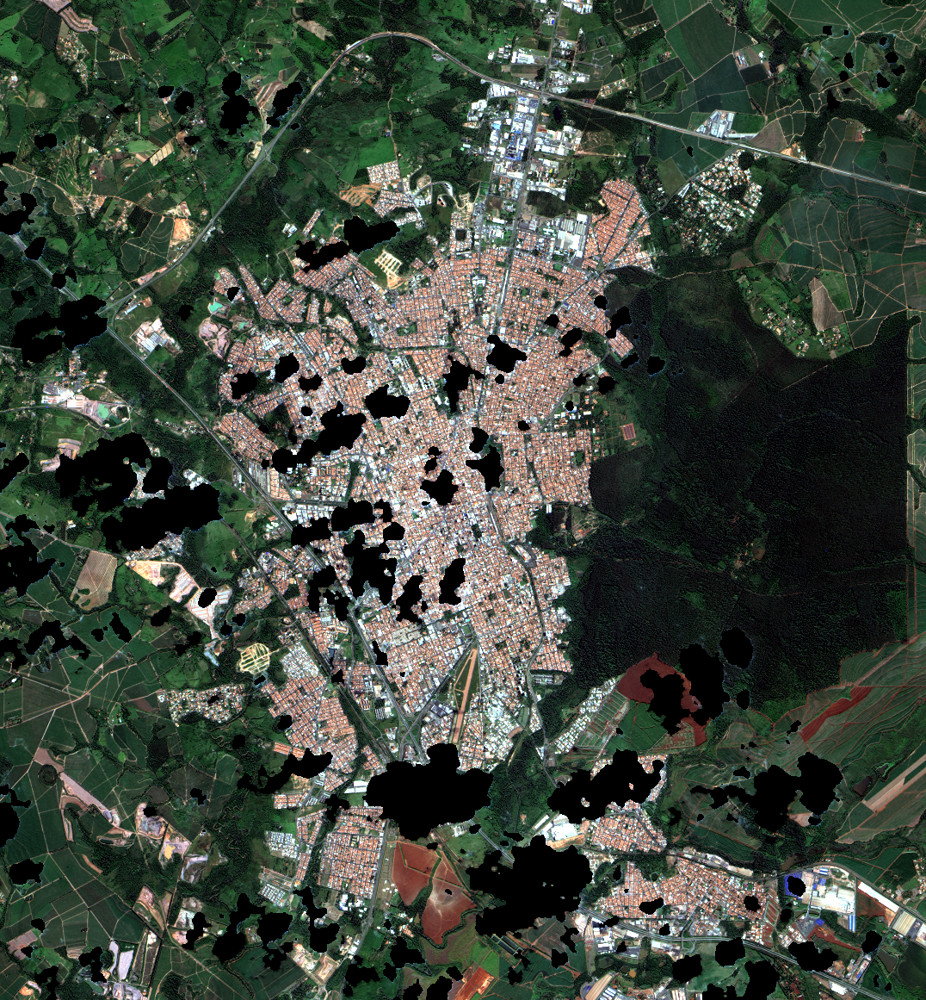

In [5]:
import folium

# Reduz a imagem para tornar o mapa mais leve
MAX_DIM = 1200
fator = max(1, int(np.ceil(max(H_CBERS, W_CBERS) / MAX_DIM)))
forma_folium = (H_CBERS // fator, W_CBERS // fator)

with rasterio.open(cbers_mascarado) as src:
    rgb = src.read(
        (1, 2, 3),
        out_shape=(3, *forma_folium),
        resampling=Resampling.average
    ).astype("float32")
    nodata_folium = src.nodata

if nodata_folium is not None:
    rgb[:, rgb[0] <= nodata_folium + 1] = np.nan

imagem_folium = np.dstack([
    (np.nan_to_num(ac.stretch(b), nan=0) * 255).astype("uint8")
    for b in rgb
])

# Limites da imagem em latitude/longitude
west, south, east, north = transform_bounds(
    CRS_ALVO, "EPSG:4326", *BOUNDS_CBERS
)

centro = [(south + north) / 2, (west + east) / 2]

mapa = folium.Map(
    location=centro,
    zoom_start=12,
    tiles="https://{s}.tile-cyclosm.openstreetmap.fr/cyclosm/{z}/{x}/{y}.png",
    attr='&copy; <a href="https://github.com">CyclOSM</a> tiles courtesy of <a href="https://www.openstreetmap.org/">OpenStreetMap</a>'
)

folium.raster_layers.ImageOverlay(
    image=imagem_folium,
    bounds=[[south, west], [north, east]],
    opacity=1.0,
    cross_origin=False,
    name="CBERS-4A com lacunas"
).add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa.fit_bounds([[south, west], [north, east]])

mapa

## 1. Montando o mosaico Sentinel-2

No script original, essa etapa era feita pelo Google Earth Engine. Aqui vamos montar o mosaico
direto do **STAC do Microsoft Planetary Computer**, uma maneira mais dinâmica, em que você baixa as
imagens sem conta, sem autenticação e sem esperar exportação.

**A grade é definida pelo CBERS**, e não pelo Sentinel-2: mesmo CRS, mesma origem, resolução de
10 m e uma margem de 240 m além da AOI (`MARGEM_M`). Essa margem é necessária porque o corregistro
desloca a imagem, e sem folga a borda ficaria sem dado; além disso, o AROSICS precisa de contexto
em volta das lacunas para encontrar pontos de amarração.

### 1.1 Composição por data mais próxima

Para cada pixel, usamos a cena Sentinel-2 **mais próxima em data** que esteja limpa **naquele
pixel**, segundo a banda `SCL` do produto L2A. Isso é melhor que uma mediana temporal, pois preserva
a textura real de uma data, em vez de misturar várias datas.

Atenção: pixels vizinhos podem vir de datas diferentes. Por isso gravamos a banda **`delta_days`**,
que registra a diferença em dias de cada pixel em relação à data do CBERS.

A célula abaixo define a grade do mosaico e busca as cenas Sentinel-2 L2A com até `NUVEM_MAX`% de
nuvem numa janela de `JANELA_DIAS` dias antes e depois da data do CBERS. O resultado é uma tabela
ordenada pela proximidade de data, com o `idx` de cada cena.

In [6]:
import pandas as pd
import planetary_computer as pc
from pystac_client import Client

# grade alvo: 10 m, encaixada na grade do CBERS, com margem
res_s2 = 10.0
minx = math.floor((BOUNDS_CBERS.left - MARGEM_M) / res_s2) * res_s2
miny = math.floor((BOUNDS_CBERS.bottom - MARGEM_M) / res_s2) * res_s2
maxx = math.ceil((BOUNDS_CBERS.right + MARGEM_M) / res_s2) * res_s2
maxy = math.ceil((BOUNDS_CBERS.top + MARGEM_M) / res_s2) * res_s2
W_S2, H_S2 = int((maxx - minx) / res_s2), int((maxy - miny) / res_s2)
T_S2 = Affine(res_s2, 0, minx, 0, -res_s2, maxy)
BOUNDS_ALVO = (minx, miny, maxx, maxy)

bbox_4326 = transform_bounds(CRS_ALVO, "EPSG:4326", *BOUNDS_ALVO)
data_ref = datetime.fromisoformat(DATA_ISO).replace(tzinfo=timezone.utc)
ini = (data_ref - timedelta(days=JANELA_DIAS)).date().isoformat()
fim = (data_ref + timedelta(days=JANELA_DIAS)).date().isoformat()

catalogo = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                       modifier=pc.sign_inplace)
itens = list(catalogo.search(collections=["sentinel-2-l2a"], bbox=list(bbox_4326),
                             datetime=f"{ini}/{fim}",
                             query={"eo:cloud_cover": {"lt": NUVEM_MAX}}).items())

def delta_dias(item):
    d = datetime.fromisoformat(str(item.properties["datetime"]).replace("Z", "+00:00"))
    return (d - data_ref).days

itens.sort(key=lambda it: abs(delta_dias(it)))
print(f"grade do mosaico: {W_S2} x {H_S2} px @ {res_s2:g} m ({CRS_ALVO})")
print(f"{len(itens)} cenas Sentinel-2 entre {ini} e {fim}")
print("nuvem_cena_% é da CENA INTEIRA (~110 km), não da sua AOI — a prévia da "
      "próxima seção mede na AOI.\n")

df_s2 = pd.DataFrame([{
    "idx": i,
    "data": str(it.properties["datetime"])[:10],
    "delta_dias": delta_dias(it),
    "nuvem_cena_%": round(float(it.properties.get("eo:cloud_cover", float("nan"))), 1),
    "tile": it.properties.get("s2:mgrs_tile", "?"),
    "baseline": str(it.properties.get("s2:processing_baseline", "?")),
    "id": it.id,
} for i, it in enumerate(itens)])
df_s2.head(20)

grade do mosaico: 1340 x 1442 px @ 10 m (EPSG:32723)
27 cenas Sentinel-2 entre 2026-01-15 e 2026-04-15
nuvem_cena_% é da CENA INTEIRA (~110 km), não da sua AOI — a prévia da próxima seção mede na AOI.



,idx,data,delta_dias,nuvem_cena_%,tile,baseline,id
0,0,2026-02-27,-2,79.4,22KHA,05.12,S2C_MSIL2A_20260227T132231_R038_T22KHA_2026022...
1,1,2026-03-04,3,18.0,23KKR,05.12,S2B_MSIL2A_20260304T132229_R038_T23KKR_2026030...
2,2,2026-03-04,3,25.9,22KHA,05.12,S2B_MSIL2A_20260304T132229_R038_T22KHA_2026030...
3,3,2026-02-22,-7,67.4,23KKR,05.12,S2A_MSIL2A_20260222T132851_R038_T23KKR_2026022...
4,4,2026-02-22,-7,66.0,22KHA,05.12,S2A_MSIL2A_20260222T132851_R038_T22KHA_2026022...
5,5,2026-02-22,-7,42.0,23KKR,05.12,S2B_MSIL2A_20260222T132229_R038_T23KKR_2026022...
6,6,2026-02-22,-7,39.1,22KHA,05.12,S2B_MSIL2A_20260222T132229_R038_T22KHA_2026022...
7,7,2026-02-17,-12,2.7,23KKR,05.12,S2C_MSIL2A_20260217T132231_R038_T23KKR_2026021...
8,8,2026-02-17,-12,3.0,22KHA,05.12,S2C_MSIL2A_20260217T132231_R038_T22KHA_2026021...
9,9,2026-03-14,13,39.1,23KKR,05.12,S2B_MSIL2A_20260314T132229_R038_T23KKR_2026031...


### Funções de leitura

Duas funções de apoio, usadas até o fim da seção 1:

- `offset_da_baseline` corrige o deslocamento de −1000 que a ESA passou a aplicar na reflectância
  do L2A a partir da *processing baseline* 04.00 (janeiro de 2022);
- `ler_para_grade` lê uma banda e a reprojeta direto para a grade do CBERS. Com uma grade mais
  grossa, ela aproveita as versões reduzidas do arquivo, e é assim que as prévias ficam rápidas.

In [7]:
# Funções de leitura usadas daqui até o fim da seção 1.
ASSETS = {"red": "B04", "green": "B03", "blue": "B02", "nir": "B08"}
LIMIAR_BASELINE = datetime(2022, 1, 25, tzinfo=timezone.utc)


def offset_da_baseline(item):
    """Desde a baseline 04.00 a reflectância do L2A vem com offset de -1000."""
    baseline = str(item.properties.get("s2:processing_baseline", ""))
    quando = datetime.fromisoformat(str(item.properties["datetime"]).replace("Z", "+00:00"))
    try:
        return (-1000.0 if float(baseline) >= 4.0 else 0.0), baseline
    except ValueError:
        return (-1000.0 if quando >= LIMIAR_BASELINE else 0.0), baseline


def ler_para_grade(href, dtype="float32", resampling=Resampling.bilinear,
                   forma=None, transform=None):
    """Lê um asset e o reprojeta para a grade alvo (CRS e transform do CBERS).

    Com `forma` e `transform` lê para uma grade mais grossa — é assim que as
    prévias saem baratas, aproveitando as visões reduzidas do COG.
    """
    forma = forma or (H_S2, W_S2)
    transform = T_S2 if transform is None else transform
    saida = np.zeros(forma, dtype=dtype)
    with rasterio.open(href) as src:
        b = transform_bounds(CRS_ALVO, src.crs, *BOUNDS_ALVO, densify_pts=21)
        jan = from_bounds(*b, src.transform).round_offsets().round_lengths()
        c0, r0 = int(jan.col_off) - 4, int(jan.row_off) - 4
        c1 = int(jan.col_off + jan.width) + 4
        r1 = int(jan.row_off + jan.height) + 4
        c0, r0 = max(0, c0), max(0, r0)
        c1, r1 = min(src.width, c1), min(src.height, r1)
        if c1 <= c0 or r1 <= r0:
            return None                       # a cena não cobre a AOI
        jan = Window(c0, r0, c1 - c0, r1 - r0)
        arr = src.read(1, window=jan)
        reproject(source=arr, destination=saida,
                  src_transform=src.window_transform(jan), src_crs=src.crs,
                  dst_transform=transform, dst_crs=CRS_ALVO, resampling=resampling)
    return saida

### 1.2 Vendo as cenas candidatas antes de escolher

A coluna `nuvem_cena_%` da tabela é referente à **cena inteira** do Sentinel-2, e a nossa AOI é só
um recorte dela. Uma cena com 40% de nuvem pode estar limpa em cima da sua área, e uma com 3% pode
ter justamente aquela nuvem no seu recorte.

Por isso, vamos ler uma versão reduzida de cada candidata **só na AOI**. Para cada imagem, aparece a
cor natural na sua área, quanto dela a cena **cobre** e a fração limpa **medida ali**. É a mesma
ideia da escolha de cena da Aula 00.

Só entram na prévia as candidatas com até 60% de nuvem na cena (`NUVEM_MAX_PREVIA`), por isso alguns
`idx` da tabela não aparecem.

[1] 2026-03-04  Δ  +3 d | cobre 100.0% da AOI | limpo (SCL)  94.6% | 23KKR
[2] 2026-03-04  Δ  +3 d | cobre 100.0% da AOI | limpo (SCL)  97.0% | 22KHA
[5] 2026-02-22  Δ  -7 d | cobre 100.0% da AOI | limpo (SCL)  52.6% | 23KKR
[6] 2026-02-22  Δ  -7 d | cobre 100.0% da AOI | limpo (SCL)  52.7% | 22KHA
[7] 2026-02-17  Δ -12 d | cobre 100.0% da AOI | limpo (SCL)  88.7% | 23KKR
[8] 2026-02-17  Δ -12 d | cobre 100.0% da AOI | limpo (SCL)  88.6% | 22KHA
[9] 2026-03-14  Δ +13 d | cobre 100.0% da AOI | limpo (SCL) 100.0% | 23KKR
[10] 2026-03-14  Δ +13 d | cobre 100.0% da AOI | limpo (SCL) 100.0% | 22KHA


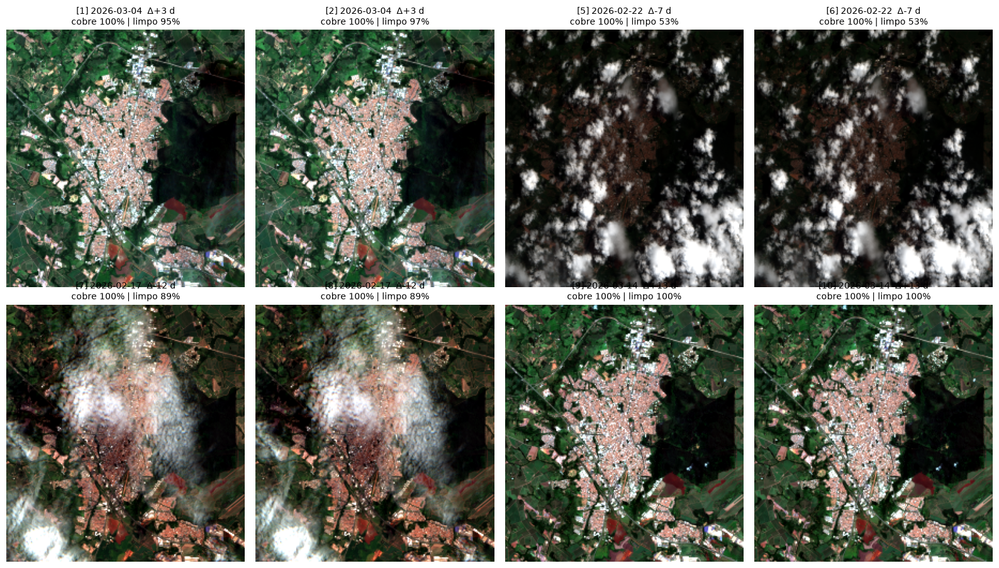

In [8]:
#| label: fig-previas-s2
#| fig-cap: "Prévia das candidatas Sentinel-2 na AOI: cobertura e fração limpa medidas ali."
MAX_PREVIA = 8
NUVEM_MAX_PREVIA = 60.0

# Mantém os índices originais e exclui cenas com mais de 60% de nuvem
itens_previa = [
    (i, item) for i, item in enumerate(itens)
    if float(item.properties.get("eo:cloud_cover", 0)) <= NUVEM_MAX_PREVIA
][:MAX_PREVIA]

fator_p = max(1, int(np.ceil(max(H_S2, W_S2) / 280)))
forma_p = (max(1, H_S2 // fator_p), max(1, W_S2 // fator_p))
T_p = T_S2 * Affine.scale(fator_p, fator_p)

previas = []
for i, item in itens_previa:
    if any(a not in item.assets for a in ("B04", "B03", "B02", "SCL")):
        continue

    scl = ler_para_grade(item.assets["SCL"].href, "uint8",
                         Resampling.nearest, forma_p, T_p)
    if scl is None:
        continue

    off, _ = offset_da_baseline(item)
    rgb = [
        np.clip(
            ler_para_grade(item.assets[a].href, "float32",
                           Resampling.average, forma_p, T_p) + off,
            0, 32000
        )
        for a in ("B04", "B03", "B02")
    ]

    dentro = rgb[0] > 0
    limpo = ~np.isin(scl, CLASSES_NUVEM) & dentro

    previas.append({
        "idx": i,
        "item": item,
        "rgb": rgb,
        "cobre_aoi": float(dentro.mean()),
        "limpo_aoi": float(limpo.mean())
    })

    print(f"[{i}] {str(item.properties['datetime'])[:10]}  "
          f"Δ{delta_dias(item):>+4} d | cobre {dentro.mean():6.1%} da AOI | "
          f"limpo (SCL) {limpo.mean():6.1%} | "
          f"{item.properties.get('s2:mgrs_tile', '?')}")

colunas = 4
linhas = max(1, int(np.ceil(len(previas) / colunas)))
fig, axes = plt.subplots(linhas, colunas,
                         figsize=(4 * colunas, 4.5 * linhas),
                         squeeze=False)

for ax, pv in zip(axes.ravel(), previas):
    ax.imshow(np.dstack([
        ac.stretch(np.where(pv["rgb"][0] > 0, b, np.nan))
        for b in pv["rgb"]
    ]))
    ax.set_title(
        f"[{pv['idx']}] {str(pv['item'].properties['datetime'])[:10]}  "
        f"Δ{delta_dias(pv['item']):+d} d\n"
        f"cobre {pv['cobre_aoi']:.0%} | limpo {pv['limpo_aoi']:.0%}",
        fontsize=10
    )

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

### 1.3 Escolhendo as cenas

`ESCOLHA_S2 = None` deixa a escolha no automático (as `MAX_CENAS` mais próximas em data). Uma
**lista de `idx`** define as imagens que serão utilizadas, e a ordem da lista é a **ordem de
preferência**: a primeira preenche o que puder, a segunda preenche o que sobrou, e assim por diante.

Aqui, vamos usar as imagens 1, 2, 9 e 10. A 1 e a 2 são a mesma data (04/03/2026, 3 dias depois da
nossa imagem CBERS) em dois *tiles* do Sentinel-2 (23KKR e 22KHA), porque a nossa AOI cai na emenda
entre eles. As duas estão praticamente limpas e vão preencher a maior parte das lacunas. A 9 e a 10
são o mesmo caso, com data de 14/03/2026, e servem para preencher uma área de névoa na parte
sudoeste da imagem.

> **Uma AOI pode cair na emenda de dois tiles.** Quando isso acontece, a mesma data aparece duas
> vezes na tabela, com `tile` diferente, e **cada uma cobre um pedaço** da sua área (a coluna
> `cobre` da prévia mostra isso). Nesse caso, coloque as duas na lista: elas se completam.

Utilizar o STAC nos permite gerar essas prévias, que facilitam a fotointerpretação, e devemos usar
essa tecnologia a nosso favor. Na célula abaixo, definimos as cenas escolhidas.

In [9]:
# None = automático (as MAX_CENAS mais próximas em data)
# lista de idx = você escolhe, na ordem de preferência. Ex.: [3, 4]
ESCOLHA_S2 = [1, 2, 9, 10]

if ESCOLHA_S2:
    selecionadas = [itens[i] for i in ESCOLHA_S2]
    print("seleção manual, nesta ordem de preferência:")
else:
    selecionadas = itens[:MAX_CENAS]
    print(f"seleção automática: as {len(selecionadas)} mais próximas em data")

for it in selecionadas:
    print(f"  Δ{delta_dias(it):>+4} d  {str(it.properties['datetime'])[:10]}  "
          f"{it.properties.get('s2:mgrs_tile', '?'):<7} {it.id}")

if not selecionadas:
    raise SystemExit("nenhuma cena selecionada — confira ESCOLHA_S2.")

seleção manual, nesta ordem de preferência:
  Δ  +3 d  2026-03-04  23KKR   S2B_MSIL2A_20260304T132229_R038_T23KKR_20260304T183249
  Δ  +3 d  2026-03-04  22KHA   S2B_MSIL2A_20260304T132229_R038_T22KHA_20260304T183249
  Δ +13 d  2026-03-14  23KKR   S2B_MSIL2A_20260314T132229_R038_T23KKR_20260314T182541
  Δ +13 d  2026-03-14  22KHA   S2B_MSIL2A_20260314T132229_R038_T22KHA_20260314T182541


### 1.4 A máscara de nuvem

O Sentinel-2 conta com uma máscara própria, a **SCL**. Nela, marcamos apenas o que é classificado
como **nuvem**: 8 (probabilidade média), 9 (probabilidade alta) e 10 (cirros). Como escolhemos as
cenas olhando a prévia, qualquer camada a mais só aumentaria o risco de remover pixels bons.

> **Caso você perceba sombras de nuvem que não foram mascaradas**, volte em **0. Configuração** e
> acrescente a classe **3 (sombra de nuvem)** em `CLASSES_NUVEM`. Fica o aviso: o SCL confunde
> **água escura com sombra de nuvem** com frequência, e isso costuma gerar buracos em represas e
> rios. Confira o painel "candidatas com dado limpo, por pixel" depois.

Se você escolheu imagens totalmente limpas, pode definir `MASCARA_SCL = False` em **0.
Configuração**. Isso desliga a filtragem pelo SCL e usa as cenas exatamente como vieram.

Sobre a regra de escolha por pixel: entre as candidatas com dado limpo, vence a **primeira da
ordem**, que é a mais próxima em data no automático ou, no nosso caso, a que colocamos primeiro em
`ESCOLHA_S2` (cena 1 > cena 2 > cena 9 > cena 10).

A célula abaixo lê as cenas escolhidas, monta a máscara de cada uma, faz a escolha por pixel e
monta o mosaico, mostrando quantos pixels vieram de cada cena.

In [10]:
#| label: tbl-cenas-s2
# ---- 1. lê as selecionadas e monta a máscara de cada uma -------------------
candidatas, usadas = [], []
print(f"{'cena':<44} {'delta':>6} {'cobre':>7} {'limpo':>7}")

for item in selecionadas:
    if any(a not in item.assets for a in list(ASSETS.values()) + ["SCL"]):
        continue
    bandas = [ler_para_grade(item.assets[a].href) for a in ASSETS.values()]
    if any(b is None for b in bandas):
        continue

    offset, baseline = offset_da_baseline(item)
    pilha = np.clip(np.stack(bandas) + offset, 0, 32000)
    dentro = (pilha > 0).any(axis=0)          # onde esta cena cobre a AOI

    limpo = dentro.copy()
    if MASCARA_SCL:
        scl = ler_para_grade(item.assets["SCL"].href, "uint8", Resampling.nearest)
        if scl is not None:
            nuvem = np.isin(scl, CLASSES_NUVEM)
            if DILATA_NUVEM_PX:
                nuvem = binary_dilation(nuvem, iterations=DILATA_NUVEM_PX)
            limpo &= ~nuvem

    if not limpo.any():
        print(f"{item.id[:44]:<44} {delta_dias(item):>+6} {dentro.mean():>6.1%} "
              f"{0.0:>6.1%}  descartada")
        continue

    candidatas.append({"item": item, "pilha": pilha, "limpo": limpo,
                       "delta": delta_dias(item), "baseline": baseline,
                       "offset": offset, "cobre": float(dentro.mean()),
                       "frac_limpa": float(limpo.mean())})
    print(f"{item.id[:44]:<44} {delta_dias(item):>+6} {dentro.mean():>6.1%} "
          f"{limpo.mean():>6.1%}")

if not candidatas:
    raise SystemExit("nenhuma cena Sentinel-2 utilizável. Reveja ESCOLHA_S2, "
                     "ou aumente JANELA_DIAS / NUVEM_MAX.")

# ---- 2. escolha por pixel: a primeira da ordem que tiver dado limpo --------
escolha = np.full((H_S2, W_S2), -1, dtype="int16")
for i, c in enumerate(candidatas):
    falta = (escolha < 0) & c["limpo"]
    escolha[falta] = i

# ---- 3. monta o mosaico -----------------------------------------------------
n_limpos = np.sum([c["limpo"] for c in candidatas], axis=0).astype("int16")
refl = np.zeros((4, H_S2, W_S2), dtype="float32")
delta = np.zeros((H_S2, W_S2), dtype="int16")
preenchido = escolha >= 0

for i, c in enumerate(candidatas):
    sel = escolha == i
    if not sel.any():
        continue
    refl[:, sel] = c["pilha"][:, sel]
    delta[sel] = c["delta"]
    usadas.append({"id": c["item"].id,
                   "data": str(c["item"].properties["datetime"])[:10],
                   "delta_dias": c["delta"], "baseline": c["baseline"],
                   "offset": c["offset"], "cobre_aoi": round(c["cobre"], 4),
                   "frac_limpa": round(c["frac_limpa"], 4),
                   "px_usados": int(sel.sum())})
    print(f"{c['item'].id[:44]:<44} -> {sel.sum():,} px usados")

for c in candidatas:
    c.pop("pilha", None)

print(f"\ncobertura final do mosaico: {preenchido.mean():.2%} "
      f"({len(usadas)} cenas contribuíram)")
if preenchido.mean() < 0.99:
    print("Sobrou buraco. Se a cena está visivelmente limpa ali, é falso positivo do")
    print("SCL: tire a classe 3 de CLASSES_NUVEM, ou use MASCARA_SCL = False.")

cena                                          delta   cobre   limpo
S2B_MSIL2A_20260304T132229_R038_T23KKR_20260     +3 100.0%  94.5%
S2B_MSIL2A_20260304T132229_R038_T22KHA_20260     +3 100.0%  97.0%
S2B_MSIL2A_20260314T132229_R038_T23KKR_20260    +13 100.0% 100.0%
S2B_MSIL2A_20260314T132229_R038_T22KHA_20260    +13 100.0% 100.0%
S2B_MSIL2A_20260304T132229_R038_T23KKR_20260 -> 1,826,028 px usados
S2B_MSIL2A_20260304T132229_R038_T22KHA_20260 -> 47,447 px usados
S2B_MSIL2A_20260314T132229_R038_T23KKR_20260 -> 58,805 px usados

cobertura final do mosaico: 100.00% (3 cenas contribuíram)


### Gravando o mosaico

O mosaico é gravado como um GeoTIFF de **6 bandas** em `int16`: vermelho, verde, azul e NIR
(reflectância × 10.000), `delta_days` e `valid` (1 onde o mosaico tem dado). Ao lado dele vai um
`.params.json` com as cenas usadas e os parâmetros da busca.

In [11]:
s2_10m = P["interim"] / f"S2_{DATA}_10m.tif"
perfil_s2 = dict(driver="GTiff", dtype="int16", count=6, height=H_S2, width=W_S2,
                 transform=T_S2, crs=CRS_ALVO, nodata=NODATA, compress="deflate",
                 predictor=2, tiled=True, blockxsize=512, blockysize=512,
                 BIGTIFF="IF_SAFER", interleave="band")

with rasterio.open(s2_10m, "w", **perfil_s2) as dst:
    for i in range(4):
        b = np.where(preenchido, np.rint(refl[i]), NODATA)
        dst.write(b.astype("int16"), i + 1)
    dst.write(np.where(preenchido, delta, -32768).astype("int16"), 5)
    dst.write(preenchido.astype("int16"), 6)
    for i, nome in enumerate(["red", "green", "blue", "nir", "delta_days", "valid"], 1):
        dst.set_band_description(i, nome)
    dst.update_tags(ORDEM_BANDAS="RGBN", FATOR_ESCALA="10000",
                    CENAS=json.dumps([u["id"] for u in usadas]))

s2_10m.with_suffix(".params.json").write_text(json.dumps(
    {"gerado_em": datetime.now().isoformat(timespec="seconds"), "aula": "03",
     "etapa": "mosaico S2", "data_referencia": DATA_ISO,
     "janela_dias": JANELA_DIAS, "nuvem_max": NUVEM_MAX, "margem_m": MARGEM_M,
          "mascara_scl": MASCARA_SCL, "classes_nuvem": list(CLASSES_NUVEM),
     "dilata_nuvem_px": DILATA_NUVEM_PX, "cenas": usadas,
     "cobertura": float(preenchido.mean())},
    indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Escrito: {s2_10m.name}  ({s2_10m.stat().st_size / 1024**2:.1f} MB)")

Escrito: S2_20260301_10m.tif  (10.7 MB)


### Conferindo o mosaico

Três painéis: o mosaico em cor natural, o `delta_days` de cada pixel e **quantas candidatas tinham
dado limpo em cada pixel**. Onde esse número for 0, o mosaico ficou vazio: ou nenhuma cena cobre
aquele ponto, ou o SCL marcou nuvem em todas. Se a prévia mostra a imagem limpa ali, é o SCL
errando; ajuste `CLASSES_NUVEM` ou use `MASCARA_SCL = False`.

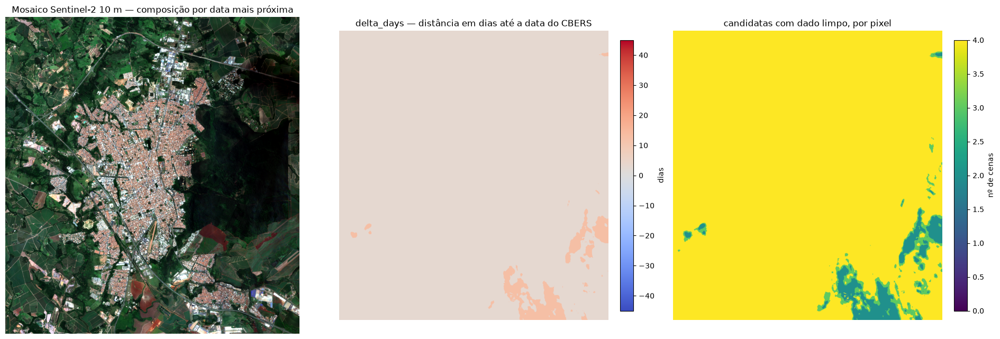

In [12]:
#| label: fig-mosaico-s2
#| fig-cap: "Mosaico Sentinel-2 de 10 m, procedência temporal e candidatas limpas por pixel."
fig, ax = plt.subplots(1, 3, figsize=(19, 6.5))
rgb = np.dstack([ac.stretch(np.where(preenchido, refl[i], np.nan)) for i in range(3)])
ax[0].imshow(rgb)
ax[0].set_title("Mosaico Sentinel-2 10 m — composição por data mais próxima")

im = ax[1].imshow(np.where(preenchido, delta, np.nan), cmap="coolwarm",
                  vmin=-JANELA_DIAS, vmax=JANELA_DIAS)
ax[1].set_title("delta_days — distância em dias até a data do CBERS")
fig.colorbar(im, ax=ax[1], fraction=0.046, pad=0.04, label="dias")

# quantas candidatas tinham dado limpo em cada pixel. Onde é 0, o mosaico ficou
# com buraco: ou nenhuma cena cobre ali, ou o SCL marcou nuvem em todas.
im2 = ax[2].imshow(n_limpos, cmap="viridis", vmin=0, vmax=max(1, int(n_limpos.max())))
ax[2].set_title("candidatas com dado limpo, por pixel")
fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04, label="nº de cenas")

for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

if (n_limpos == 0).any():
    print(f"{int((n_limpos == 0).sum()):,} px sem nenhuma candidata limpa "
          f"({(n_limpos == 0).mean():.2%} da grade) — são os brancos do mosaico.")
    print("Compare com a prévia: se a imagem está limpa ali, é o SCL errando. "
          "Ajuste CLASSES_NUVEM ou ponha MASCARA_SCL = False.")

## 2. Super-resolução com o SEN2SR

O SEN2SR leva o Sentinel-2 de 10 m para 2,5 m. Ele não inventa informação: o modelo aprendeu como
imagens de alta resolução costumam ser e usa isso para reconstruir detalhes **plausíveis**.

A célula abaixo baixa os pesos do modelo com o `mlstac` (só na primeira vez) e carrega o modelo na
GPU, se houver, ou na CPU.

In [13]:
import mlstac
import torch

URLS = {"lite": ("https://huggingface.co/tacofoundation/sen2sr/resolve/main/"
                 "SEN2SRLite/NonReference_RGBN_x4/mlm.json"),
        "full": ("https://huggingface.co/tacofoundation/sen2sr/resolve/main/"
                 "SEN2SR/NonReference_RGBN_x4/mlm.json")}
# os pesos ficam ao lado da pasta de dados: model/ localmente, e no Drive no Colab
# (assim não são baixados de novo a cada sessão)
DIR_MODELO = (Path(P["base"]).parent / "model"
              / ("SEN2SRLite_RGBN" if MODELO == "lite" else "SEN2SR_RGBN"))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("dispositivo:", device)

if not DIR_MODELO.exists():
    DIR_MODELO.parent.mkdir(parents=True, exist_ok=True)
    print(f"baixando os pesos ({MODELO})...")
    mlstac.download(file=URLS[MODELO], output_dir=str(DIR_MODELO))

try:
    modelo = mlstac.load(str(DIR_MODELO)).compiled_model(device=device)
except ImportError as e:
    if "mamba" in str(e).lower() or "causal_conv1d" in str(e).lower():
        raise SystemExit("O modelo 'full' exige mamba-ssm com kernels CUDA compilados. "
                         "Use MODELO = 'lite'.")
    raise
print("modelo carregado")

dispositivo: cpu
modelo carregado


### Rodando a super-resolução em blocos

O modelo processa blocos de 128 × 128 pixels, com sobreposição de 32 pixels entre eles. Nas
sobreposições, os resultados são combinados com pesos que diminuem em direção à borda do bloco,
para não aparecerem emendas. Antes disso, as eventuais lacunas do mosaico são preenchidas
temporariamente com o pixel válido mais próximo, porque o modelo não aceita valores vazios. Os
resultados vão sendo acumulados em disco, então o uso de memória não depende do tamanho da cena.

In [14]:
import sys
import time

stride = TILE - OVERLAP
tile_hr = TILE * FATOR
margem_hr = OVERLAP * FATOR // 2

arr = refl / 10000.0                       # o modelo espera reflectância 0-1
valid = preenchido.copy()

if not valid.all():
    _, idx = distance_transform_edt(~valid, return_distances=True, return_indices=True)
    arr = arr[:, idx[0], idx[1]]           # vizinho mais próximo nos buracos
arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0).astype("float32")

def dim_pad(n):
    return TILE if n <= TILE else TILE + math.ceil((n - TILE) / stride) * stride

Hp, Wp = dim_pad(H_S2), dim_pad(W_S2)
arr_p = np.pad(arr, ((0, 0), (0, Hp - H_S2), (0, Wp - W_S2)), mode="reflect")
valid_p = np.pad(valid, ((0, Hp - H_S2), (0, Wp - W_S2)), mode="constant",
                 constant_values=False)
ys = list(range(0, Hp - TILE + 1, stride))
xs = list(range(0, Wp - TILE + 1, stride))
print(f"entrada {W_S2} x {H_S2} -> acolchoado {Wp} x {Hp} -> "
      f"{len(ys) * len(xs)} blocos de {TILE}x{TILE}")

tmp = Path(tempfile.mkdtemp(prefix="sen2sr_"))
Hh, Wh = Hp * FATOR, Wp * FATOR
acc = np.lib.format.open_memmap(tmp / "acc.npy", mode="w+", dtype="float32",
                                shape=(4, Hh, Wh))
wsum = np.lib.format.open_memmap(tmp / "w.npy", mode="w+", dtype="float32",
                                 shape=(Hh, Wh))

rampa = np.linspace(1e-3, 1.0, margem_hr, dtype="float32")
perfil_peso = np.ones(tile_hr, dtype="float32")
perfil_peso[:margem_hr] = rampa
perfil_peso[-margem_hr:] = rampa[::-1]
peso = perfil_peso[:, None] * perfil_peso[None, :]

def barra_progresso(atual, total, inicio, largura=50):
    # mesmo formato da barra de progresso do AROSICS
    frac = atual / total
    cheio = int(round(largura * frac))
    decorrido = int(time.time() - inicio)
    h, resto = divmod(decorrido, 3600)
    m, s = divmod(resto, 60)
    sys.stdout.write(f"\r\tprogress: |{'=' * cheio}{'-' * (largura - cheio)}| "
                     f"{frac * 100:5.1f}% Complete  => {h}:{m:02d}:{s:02d}")
    sys.stdout.flush()

total_blocos = len(ys) * len(xs)
print("Super-resolvendo com o SEN2SR...")
inicio = time.time()
feitos = pulados = 0
with torch.no_grad():
    for y0 in ys:
        for x0 in xs:
            if not valid_p[y0:y0 + TILE, x0:x0 + TILE].any():
                pulados += 1
                barra_progresso(feitos + pulados, total_blocos, inicio)
                continue
            bloco = np.ascontiguousarray(arr_p[:, y0:y0 + TILE, x0:x0 + TILE])
            X = torch.from_numpy(bloco[None]).float().to(device)
            pred = modelo(X).detach().cpu().numpy()[0]
            Y0, X0 = y0 * FATOR, x0 * FATOR
            acc[:, Y0:Y0 + tile_hr, X0:X0 + tile_hr] += pred * peso
            wsum[Y0:Y0 + tile_hr, X0:X0 + tile_hr] += peso
            feitos += 1
            barra_progresso(feitos + pulados, total_blocos, inicio)
    print()
    duracao = time.time() - inicio
    print(f"blocos processados: {feitos} | pulados (vazios): {pulados}")
    print(f"tempo da super-resolução: {duracao / 60:.1f} min "
          f"({duracao / max(feitos, 1):.2f} s por bloco)")

del modelo
if device.type == "cuda":
    torch.cuda.empty_cache()

entrada 1340 x 1442 -> acolchoado 1376 x 1472 -> 210 blocos de 128x128
Super-resolvendo com o SEN2SR...
	progress: |==================================================| 100.0% Complete  => 0:00:13
blocos processados: 210 | pulados (vazios): 0
tempo da super-resolução: 0.2 min (0.06 s por bloco)


### Gravando o resultado

O resultado é gravado em reflectância 0–1 (`float32`), com 2,5 m de resolução e o nome de cada
banda. Os pixels que estavam vazios no mosaico voltam a ficar sem dado.

In [15]:
Hs, Ws = H_S2 * FATOR, W_S2 * FATOR
valid_sr = np.repeat(np.repeat(valid, FATOR, axis=0), FATOR, axis=1)

s2_sr = P["interim"] / f"S2_{DATA}_SR2p5m.tif"
perfil_sr = dict(driver="GTiff", dtype="float32", count=4, height=Hs, width=Ws,
                 transform=T_S2 * Affine.scale(1 / FATOR), crs=CRS_ALVO,
                 nodata=np.nan, compress="deflate", predictor=3, tiled=False,
                 BIGTIFF="IF_SAFER", interleave="band")

with rasterio.open(s2_sr, "w", **perfil_sr) as dst:
    for r0 in range(0, Hs, 2048):
        r1 = min(r0 + 2048, Hs)
        bloco = (acc[:, r0:r1, :Ws] / np.maximum(wsum[r0:r1, :Ws], 1e-6)).astype("float32")
        bloco[:, ~valid_sr[r0:r1, :Ws]] = np.nan
        dst.write(bloco, window=Window(0, r0, Ws, r1 - r0))
    for i, nome in enumerate(["red", "green", "blue", "nir"], 1):
        dst.set_band_description(i, nome)      # rótulos: as etapas seguintes leem daqui
    dst.update_tags(MODELO=f"SEN2SR-{MODELO}", RESOLUCAO_M=str(10 / FATOR))

del acc, wsum
for f in tmp.glob("*.npy"):
    f.unlink()
tmp.rmdir()
print(f"Escrito: {s2_sr.name}  ({Ws} x {Hs} px @ {10 / FATOR} m, "
      f"{s2_sr.stat().st_size / 1024**2:.1f} MB)")

Escrito: S2_20260301_SR2p5m.tif  (5360 x 5768 px @ 2.5 m, 325.5 MB)


O mesmo trecho antes (10 m) e depois (2,5 m) da super-resolução:

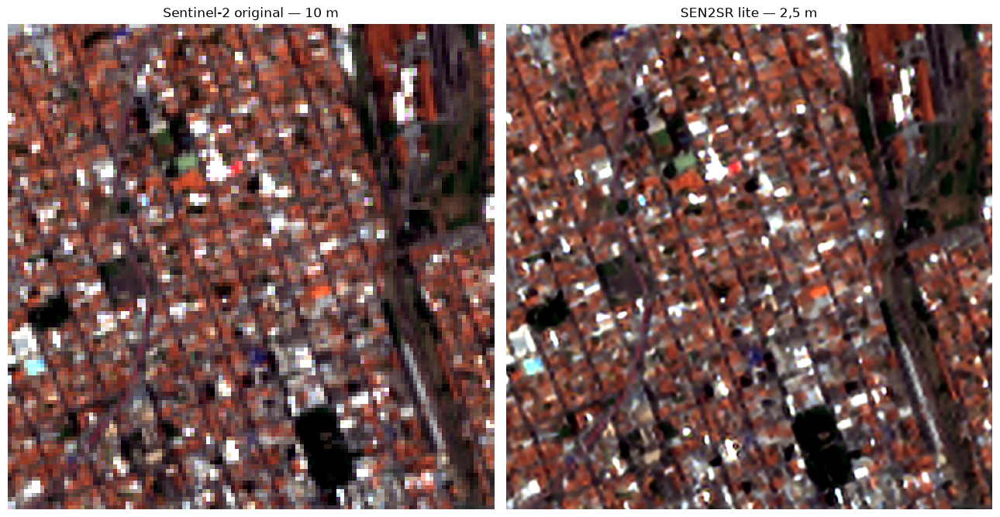

In [16]:
#| label: fig-sen2sr-zoom
#| fig-cap: "O mesmo trecho em 10 m e depois da super-resolução, em 2,5 m."
# 10 m x 2,5 m no mesmo pedaço de terreno
lado = min(120, H_S2 // 3, W_S2 // 3)
r0, c0 = H_S2 // 2 - lado // 2, W_S2 // 2 - lado // 2
antes = refl[:3, r0:r0 + lado, c0:c0 + lado] / 10000.0
with rasterio.open(s2_sr) as src:
    depois = src.read((1, 2, 3), window=Window(c0 * FATOR, r0 * FATOR,
                                               lado * FATOR, lado * FATOR))

fig, ax = plt.subplots(1, 2, figsize=(13, 6.6))
ax[0].imshow(np.dstack([ac.stretch(b) for b in antes]))
ax[0].set_title("Sentinel-2 original — 10 m")
ax[1].imshow(np.dstack([ac.stretch(b) for b in depois]))
ax[1].set_title(f"SEN2SR {MODELO} — 2,5 m")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

## 3. Reamostragem para 2 m e corregistro com o AROSICS

Duas imagens de satélites diferentes nunca estão perfeitamente sobrepostas: diferenças de
ortorretificação, do modelo de elevação usado e do relevo produzem deslocamentos de um a alguns
pixels.

O **AROSICS** (Scheffler et al., 2017) resolve isso por correlação de fase: encontra pontos de
amarração numa malha regular, mede o deslocamento em cada um, descarta os não confiáveis e ajusta a
imagem.

Dois cuidados importantes:

- **a correlação de fase não é afetada por diferenças lineares de brilho**, então não importa que as
  duas imagens tenham brilho diferente. Por isso, a harmonização vem *depois* do corregistro;
- **o AROSICS só procura pontos onde as DUAS imagens têm dado válido.** Por isso, passamos máscaras
  de "dado ruim": no CBERS, as lacunas de nuvem e o nodata; no S2, o que ficou fora do mosaico.

As três células seguintes preparam o corregistro: a primeira lê a cena CBERS mascarada e a máscara
da Aula 02 e confere se as lacunas coincidem; a segunda reamostra o S2 super-resolvido de 2,5 m
para a grade exata de 2 m do CBERS (convolução cúbica), levando junto uma banda de validade; a
terceira grava os arquivos temporários e as máscaras de dado ruim.

In [17]:
with rasterio.open(cbers_mascarado) as src:
    cbers = src.read().astype("float32")
    cbers_nodata = src.nodata
cbers[cbers <= -9000] = np.nan
nodata_cbers = ~np.isfinite(cbers).all(axis=0)

with rasterio.open(cloudmask) as src:
    if (src.height, src.width) != (H_CBERS, W_CBERS):
        raise ValueError("a máscara de nuvem não está na grade do CBERS. "
                         "Refaça a Aula 02 sobre este mesmo pansharpening.")
    classes = src.read(1)
lacuna = np.isin(classes, [1, 2, 3])

print(f"nodata no CBERS: {nodata_cbers.mean():.2%}")
print(f"lacuna de nuvem: {lacuna.mean():.2%}")
print(f"concordância entre a máscara e o buraco da imagem: "
      f"{(lacuna & nodata_cbers).sum() / max((lacuna | nodata_cbers).sum(), 1):.1%} (Jaccard)")

nodata no CBERS: 11.26%
lacuna de nuvem: 11.26%
concordância entre a máscara e o buraco da imagem: 100.0% (Jaccard)


In [18]:
# S2-SR de 2,5 m -> 2 m, na grade exata do CBERS
with rasterio.open(s2_sr) as src:
    sr = src.read().astype("float32")
    t_sr, crs_sr = src.transform, src.crs
    nomes_sr = [d or n for d, n in zip(src.descriptions, ac.NOMES_SAIDA)]
print("ordem das bandas do S2-SR:", nomes_sr)

sr_valid = np.isfinite(sr).all(axis=0)
if not sr_valid.all():
    _, idx = distance_transform_edt(~sr_valid, return_distances=True, return_indices=True)
    sr = sr[:, idx[0], idx[1]]

pilha = np.concatenate([sr, sr_valid.astype("float32")[None]], axis=0)
pilha_2m = np.empty((pilha.shape[0], H_CBERS, W_CBERS), dtype="float32")
for i in range(pilha.shape[0]):
    reproject(source=pilha[i], destination=pilha_2m[i],
              src_transform=t_sr, src_crs=crs_sr,
              dst_transform=T_CBERS, dst_crs=CRS_ALVO,
              resampling=Resampling.cubic, num_threads=CPUS)
del sr, pilha
print(f"S2-SR reamostrado para {RES_CBERS:g} m na grade do CBERS: "
      f"{W_CBERS} x {H_CBERS} px")

ordem das bandas do S2-SR: ['red', 'green', 'blue', 'nir']
S2-SR reamostrado para 2 m na grade do CBERS: 6456 x 6968 px


In [19]:
trab = P["interim"] / f"coreg_tmp_{DATA}"
trab.mkdir(parents=True, exist_ok=True)

perfil_tmp = dict(driver="GTiff", dtype="float32", count=cbers.shape[0],
                  height=H_CBERS, width=W_CBERS, transform=T_CBERS, crs=CRS_ALVO,
                  nodata=NODATA_TMP, compress="deflate", predictor=3, tiled=False)

ref_tmp = trab / "cbers_ref.tif"
with rasterio.open(ref_tmp, "w", **perfil_tmp) as dst:
    dst.write(np.nan_to_num(cbers, nan=NODATA_TMP))

tgt_tmp = trab / "s2sr_2m_pre_coreg.tif"
with rasterio.open(tgt_tmp, "w", **dict(perfil_tmp, count=pilha_2m.shape[0])) as dst:
    dst.write(pilha_2m)

# convenção do AROSICS: True = excluir da correlação
bad_ref = lacuna | nodata_cbers
bad_tgt = pilha_2m[-1] < 0.99
sobreposicao = float((~bad_ref & ~bad_tgt).mean())
print(f"área útil para correlação: {sobreposicao:.2%} da cena")
if sobreposicao < 0.10:
    raise SystemExit("sobreposição válida insuficiente para corregistrar.")

perfil_mask = dict(driver="GTiff", dtype="uint8", count=1, height=H_CBERS,
                   width=W_CBERS, transform=T_CBERS, crs=CRS_ALVO,
                   compress="deflate", tiled=False)
mask_ref_p, mask_tgt_p = trab / "bad_ref.tif", trab / "bad_tgt.tif"
for caminho, m in [(mask_ref_p, bad_ref), (mask_tgt_p, bad_tgt)]:
    with rasterio.open(caminho, "w", **perfil_mask) as dst:
        dst.write(m.astype("uint8"), 1)
print("máscaras de dado ruim gravadas")

área útil para correlação: 88.74% da cena
máscaras de dado ruim gravadas


### Rodando o AROSICS

O corregistro usa a banda NIR, que tem mais textura e sofre menos efeito atmosférico. Ao final, a
célula mostra quantos pontos confiáveis sobraram e o deslocamento mediano e o p90, e grava os
pontos de amarração num GeoPackage (`tiepoints.gpkg`), que você pode abrir no QGIS para ver onde
o ajuste foi bom e onde não foi. **Menos de 20 pontos confiáveis é sinal de alerta.**

Se o AROSICS falhar, a célula usa automaticamente um plano B: um deslocamento único para a imagem
inteira, estimado por correlação de fase (scikit-image).

In [20]:
#| label: tbl-coregistro
BANDA_MATCH = 4          # NIR: é a banda com mais textura e menos efeito atmosférico
sr_coreg = trab / "s2sr_2m_coreg.tif"
info_coreg = {}

try:
    from arosics import COREG_LOCAL

    CR = COREG_LOCAL(str(ref_tmp), str(tgt_tmp),
                     grid_res=GRID_RES, window_size=(JANELA_COREG, JANELA_COREG),
                     min_reliability=MIN_RELIAB, tieP_filter_level=3,
                     r_b4match=BANDA_MATCH, s_b4match=BANDA_MATCH,
                     max_shift=MAX_SHIFT, nodata=(NODATA_TMP, NODATA_TMP),
                     mask_baddata_ref=str(mask_ref_p), mask_baddata_tgt=str(mask_tgt_p),
                     path_out=str(sr_coreg), fmt_out="GTiff",
                     projectDir=str(trab), CPUs=CPUS, q=False)
    CR.correct_shifts()

    tbl = CR.CoRegPoints_table
    ok = tbl[(tbl["ABS_SHIFT"] != -9999) & (~tbl["OUTLIER"].astype(bool))]
    desloc = np.hypot(ok["X_SHIFT_M"].values, ok["Y_SHIFT_M"].values)
    info_coreg = {"metodo": "arosics local", "pontos_confiaveis": int(len(ok)),
                  "pontos_totais": int(len(tbl)),
                  "desloc_mediano_m": float(np.median(desloc)),
                  "desloc_p90_m": float(np.percentile(desloc, 90))}
    print(f"\npontos confiáveis   : {len(ok)} de {len(tbl)}")
    print(f"deslocamento mediano: {info_coreg['desloc_mediano_m']:.3f} m "
          f"({info_coreg['desloc_mediano_m'] / RES_CBERS:.3f} px)")
    print(f"deslocamento p90    : {info_coreg['desloc_p90_m']:.3f} m")
    if len(ok) < 20:
        print("AVISO: poucos pontos confiáveis. A cena pode ter pouca textura, ou a "
              "lacuna pode estar grande demais.")
    try:
        tbl.to_file(trab / "tiepoints.gpkg", driver="GPKG")
    except Exception:
        pass

except Exception as erro:
    # Plano B: deslocamento GLOBAL por correlação de fase. Não corrige
    # deformação local, mas resolve o caso comum de um deslocamento constante —
    # e é melhor que seguir sem corregistro nenhum.
    print(f"AROSICS indisponível ou falhou ({type(erro).__name__}: {erro}).")
    print("Usando o plano B: deslocamento global por correlação de fase.")
    from scipy.ndimage import shift as nd_shift
    from skimage.registration import phase_cross_correlation

    m = ~bad_ref & ~bad_tgt
    a = np.where(m, np.nan_to_num(cbers[BANDA_MATCH - 1]), 0.0)
    b = np.where(m, pilha_2m[BANDA_MATCH - 1], 0.0)
    desl, _, _ = phase_cross_correlation(a, b, upsample_factor=10)
    print(f"deslocamento estimado (linhas, colunas): {desl}")
    corr = np.stack([nd_shift(pilha_2m[i], desl, order=1, mode="nearest")
                     for i in range(pilha_2m.shape[0])])
    with rasterio.open(sr_coreg, "w",
                       **dict(perfil_tmp, count=corr.shape[0])) as dst:
        dst.write(corr)
    info_coreg = {"metodo": "correlacao de fase (global)",
                  "desloc_linhas_px": float(desl[0]), "desloc_colunas_px": float(desl[1]),
                  "desloc_mediano_m": float(np.hypot(*desl) * RES_CBERS)}

Calculating footprint polygon and actual data corner coordinates for reference image...


Polygonize progress     |==================================================| 100.0% Complete  => 0:00:00
C:\geo\geoprocessamento-cbers4a\.pixi\envs\default\Lib\site-packages\arosics\CoReg.py:122: UserWarning: The footprint of the reference image contains multiple separate image parts. AROSICS will only process the largest image part.
  warnings.warn(f'The footprint of the {self.imName} contains multiple separate image parts. '


Bounding box of calculated footprint for reference image:
	(229780.0, 7513022.0, 242692.0, 7526958.0)
Calculating footprint polygon and actual data corner coordinates for image to be shifted...
Bounding box of calculated footprint for image to be shifted:
	(229780.0, 7513022.0, 242692.0, 7526958.0)
Matching window position (X,Y): 236272.51132541327/7520013.717892986
Initializing tie points grid...
With respect to the provided bad data mask(s) 121 points of initially 1143 have been excluded.
Calculating tie point grid (1022 points) using 4 CPU cores...


	progress: |==================================================| 100.0% Complete  => 0:07:16


Found 730 matches.
Performing validity checks...
208 tie points flagged by level 1 filtering (reliability).
229 tie points flagged by level 2 filtering (SSIM).
24 tie points flagged by level 3 filtering (RANSAC)
350 valid tie points remain after filtering.
Correcting geometric shifts...


Translating progress |==================================================| 100.0% Complete  => 0:00:00
Warping progress     |==================================================| 100.0% Complete  => 0:00:03


Writing GeoArray of size (6968, 6456, 5) to C:\geo\geoprocessamento-cbers4a\colab\data\interim\coreg_tmp_20260301\s2sr_2m_coreg.tif.

pontos confiáveis   : 350 de 1022
deslocamento mediano: 11.925 m (5.962 px)
deslocamento p90    : 15.299 m


Por fim, gravamos o S2 corregistrado em 2 m (descartando os pixels com validade abaixo de 0,99)
e a banda `delta_days` na mesma grade.

In [21]:
with rasterio.open(sr_coreg) as src:
    corr = src.read().astype("float32")

valid_final = corr[-1] >= 0.99
s2_2m = corr[:4].copy()
s2_2m[:, ~valid_final] = np.nan
del corr, pilha_2m          # libera memória: são centenas de MB cada

saida_s2 = P["interim"] / f"S2_{DATA}_2m_coreg.tif"
with rasterio.open(saida_s2, "w", **dict(perfil_tmp, count=4, nodata=np.nan)) as dst:
    dst.write(s2_2m)
    for i, nome in enumerate(nomes_sr, 1):
        dst.set_band_description(i, nome)
print(f"Escrito: {saida_s2.name} | cobertura válida: {valid_final.mean():.2%}")

# procedência: de quando veio cada pixel. Vizinho mais próximo e SEM correção de
# deslocamento — esta banda documenta a data, não posiciona nada.
delta_2m = np.empty((H_CBERS, W_CBERS), dtype="int16")
reproject(source=delta, destination=delta_2m, src_transform=T_S2, src_crs=CRS_ALVO,
          dst_transform=T_CBERS, dst_crs=CRS_ALVO, resampling=Resampling.nearest)
delta_2m[~valid_final] = -32768

saida_delta = P["interim"] / f"S2_{DATA}_2m_delta_days.tif"
with rasterio.open(saida_delta, "w", **dict(perfil_tmp, count=1, dtype="int16",
                                            nodata=-32768, predictor=2)) as dst:
    dst.write(delta_2m, 1)
    dst.set_band_description(1, "delta_days")
print(f"Escrito: {saida_delta.name}")

Escrito: S2_20260301_2m_coreg.tif | cobertura válida: 99.93%
Escrito: S2_20260301_2m_delta_days.tif


## 4. Harmonização e substituição

**A normalização é feita com qual imagem de referência?** O Sentinel-2 é convertido para a escala do CBERS, e não o
contrário. Assim, o mosaico continua comparável com as outras cenas CBERS,
sem precisar reprocessar nenhuma delas.

**Por que ainda é preciso ajustar a radiometria?** As duas imagens já estão em reflectância de
superfície (BOA): o CBERS foi corrigido com o 6S na Aula 01, e o Sentinel-2 L2A já é distribuído
assim pela ESA, corrigido pelo Sen2Cor. A maior parte da correção física (atmosfera, iluminação e
calibração de cada sensor) já foi feita. O que sobra são diferenças menores entre os dois produtos:
os algoritmos de correção atmosférica (6S e Sen2Cor), a diferença de data, a geometria de aquisição
e as funções de resposta espectral das bandas. É a mesma lógica do HLS (Claverie et al., 2018), que
harmoniza Landsat-8 e Sentinel-2 com um ajuste linear por banda aplicado sobre a reflectância de
superfície.

**Como ajustar?** Pela **normalização radiométrica relativa** (RRN, *relative radiometric
normalization*) (Yuan; Elvidge, 1996): uma transformação empírica, banda a banda, que leva a imagem
a ser ajustada (o S2, $x$) para a escala da imagem de referência (o CBERS, $y$). Nos métodos
lineares, ela é uma reta $x' = a\,x + b$. Antes do ajuste, o S2 super-resolvido, que sai do SEN2SR
em reflectância 0–1, é **multiplicado por 10.000** para ficar na mesma unidade do CBERS
(reflectância × 10.000). Assim, $a$ e $b$ medem só a diferença de radiometria entre os dois
sensores. Os coeficientes são estimados só nos pixels em que as duas imagens têm dado, descartando
1% de cada extremo. O padrão é a **normalização média-desvio padrão**, mas há outras opções em
`METODO_HARM`:

- `media_desvio` (normalização média-desvio padrão): $a = s_y / s_x$ e $b = \bar{y} - a\,\bar{x}$.
  O S2 passa a ter a mesma média e o mesmo desvio-padrão do CBERS, então a **textura** da área
  preenchida combina com a do entorno;
- `regressao` (regressão linear simples por mínimos quadrados): a inclinação é $a = r\,s_y / s_x$,
  então o desvio-padrão do S2 ajustado fica $|r|\,s_y$, menor que o do CBERS sempre que a
  correlação não é perfeita. A área preenchida sai **mais lisa** que a vizinhança;
- `histograma` (casamento de histograma): ajusta a distribuição inteira por quantis, o que acomoda
  relações não lineares entre os sensores, mas não gera coeficientes para reportar;
- `minmax` (normalização mínimo-máximo): ajusta os extremos, aqui numa versão robusta, com os
  percentis 0,5 e 99,5 no lugar do mínimo e do máximo.

A RRN foi proposta para séries multitemporais de um mesmo sensor (Yuan; Elvidge, 1996), mas
transformações lineares banda a banda também têm sido usadas entre sensores com bandas
equivalentes, como o MSI e o OLI (Chen et al., 2023). Aqui ela é aplicada entre o MSI e o WPM,
cujas bandas ocupam intervalos próximos, mas não idênticos. Por isso ela corrige ganho e offset, mas
**não** a diferença entre as funções de resposta espectral das bandas, o que exigiria um fator de
ajuste de banda espectral (SBAF) (Pinto et al., 2016).

Com `ANEL_LACUNA > 0`, o ajuste é calculado só numa faixa em torno das lacunas. Isso serve para
quando a área que estava sob nuvem é muito diferente do resto da cena (mais úmida ou mais vegetada,
por exemplo).

**A transição.** Como a lacuna é um buraco no CBERS, não há o que misturar *dentro* dela. A
transição acontece do lado de fora: uma faixa estreita de CBERS válido em volta de cada lacuna é
parcialmente substituída, para que o resultado fique natural e sem cortes abruptos.

> **O piso de reflectância.** A normalização é uma reta $a\,x + b$, e se o $b$ sair negativo ela
> pode gerar valores abaixo de zero, mesmo partindo de um Sentinel-2 sem nenhum negativo. Por isso,
> o mosaico é gravado com o mesmo piso da Aula 01 (`PISO_REFLECTANCIA`), e o notebook informa
> quantos pixels de cada banda foram ajustados. Como o nodata é `-9999`, o pixel ajustado vale 0 e
> **continua valendo como dado**.

### Amostrando os pixels para o ajuste

Os coeficientes são estimados a partir de 120 janelas de 512 × 512 pixels sorteadas na cena, com
até 4.000 pixels válidos em cada. Antes disso, as bandas do S2 e do CBERS são pareadas **pelo nome
gravado nos arquivos**, e não pela posição, para evitar que o vermelho de uma seja ajustado contra
o azul da outra.

In [22]:
rng = np.random.default_rng(42)
T_AMOSTRA, N_AMOSTRAS = 512, 120
pares = {n: ([], []) for n in nomes_sr}
coletadas, tentativas = 0, 0

# As duas imagens estão em RGBN, mas em vez de confiar nisso a gente casa banda a
# banda PELO NOME gravado no arquivo. Uma troca silenciosa de R por B não quebra
# nada — só faz a harmonização ajustar o vermelho do S2 contra o azul do CBERS.
nomes_cbers = [(d or "").strip().lower() for d in NOMES]
if all(n in nomes_cbers for n in nomes_sr):
    ordem_cb = [nomes_cbers.index(n) for n in nomes_sr]
else:
    print(f"AVISO: rótulos do CBERS ({nomes_cbers}) não reconhecidos; "
          f"assumindo a mesma ordem do S2-SR.")
    ordem_cb = list(range(4))
print("pareamento banda a banda (S2 -> CBERS):",
      {n: ordem_cb[i] + 1 for i, n in enumerate(nomes_sr)})

cb_full = cbers[ordem_cb]            # (4, H, W), reflectância x10.000, NaN onde não há dado
s2_full = s2_2m                      # (4, H, W), reflectância 0-1 (a escala do SEN2SR)

# O SEN2SR trabalha em reflectância 0-1 e o CBERS está em reflectância x10.000.
# Antes de comparar, o S2 é multiplicado por ESCALA (10.000): assim as duas
# imagens ficam na mesma unidade e a reta da normalização ajusta só a
# radiometria. A conversão é feita janela a janela (e banda a banda, na montagem
# do mosaico) para não duplicar na memória uma pilha de centenas de MB.
ESC = ac.ESCALA

while coletadas < N_AMOSTRAS and tentativas < N_AMOSTRAS * 30:
    tentativas += 1
    r0 = int(rng.integers(0, max(1, H_CBERS - T_AMOSTRA)))
    c0 = int(rng.integers(0, max(1, W_CBERS - T_AMOSTRA)))
    cb = cb_full[:, r0:r0 + T_AMOSTRA, c0:c0 + T_AMOSTRA].astype("float64")
    s2 = s2_full[:, r0:r0 + T_AMOSTRA, c0:c0 + T_AMOSTRA].astype("float64") * ESC

    ok = np.isfinite(cb).all(axis=0) & np.isfinite(s2).all(axis=0)
    if ANEL_LACUNA > 0:
        buraco = ~np.isfinite(cb).all(axis=0) & np.isfinite(s2).all(axis=0)
        if not buraco.any():
            continue
        ok = ok & (distance_transform_edt(~buraco) <= ANEL_LACUNA)
        if ok.sum() < 2000:
            continue
    elif ok.mean() < 0.5:
        continue

    idx = np.flatnonzero(ok.ravel())
    if idx.size > 4000:
        idx = rng.choice(idx, 4000, replace=False)
    for i, n in enumerate(nomes_sr):
        pares[n][0].append(s2[i].ravel()[idx])
        pares[n][1].append(cb[i].ravel()[idx])
    coletadas += 1

if coletadas == 0:
    raise SystemExit("nenhuma janela com sobreposição válida suficiente para harmonizar.")
print(f"janelas amostradas: {coletadas}  "
      f"(escopo: {'anel das lacunas' if ANEL_LACUNA else 'cena inteira'})")

pareamento banda a banda (S2 -> CBERS): {'red': 1, 'green': 2, 'blue': 3, 'nir': 4}
janelas amostradas: 120  (escopo: cena inteira)


### Calculando os coeficientes

A célula abaixo calcula os coeficientes com o método escolhido em `METODO_HARM`. Tudo está em
reflectância × 10.000, e a tabela tem duas partes:

- **antes da normalização**: as médias do S2 e do CBERS nos mesmos pixels, a diferença entre elas
  (em valor e em % da média do CBERS) e a razão de contraste (desvio-padrão do S2 ÷ desvio-padrão
  do CBERS). Diferença negativa quer dizer que o S2 é mais escuro que o CBERS; razão de contraste
  acima de 1, que o S2 tem mais contraste;
- **coeficientes**: o ganho $a$ e o deslocamento $b$ da reta, e o número de pixels usados.

Nos pixels usados para calcular a reta, a média-desvio padrão deixa as médias e os desvios **iguais
por construção**, então não faz sentido conferir o resultado ali. O "depois" é avaliado na emenda,
mais abaixo.

In [23]:
#| label: tbl-harmonizacao
ajuste = {}
METODOS_HARM = ("media_desvio", "regressao", "histograma", "minmax")
if METODO_HARM not in METODOS_HARM:
    raise ValueError(f"METODO_HARM={METODO_HARM!r} desconhecido; use um de {METODOS_HARM}")

print(f"NORMALIZAÇÃO RADIOMÉTRICA RELATIVA — Sentinel-2 para a escala do CBERS, "
      f"método '{METODO_HARM}'")
print(f"Escala: reflectância x {ESC:,} (o SEN2SR, que sai em 0-1, foi multiplicado por {ESC:,})\n")
print(f"{'':<8}{' ANTES DA NORMALIZAÇÃO ':-^61}  {' COEFICIENTES ':-^30}")
print(f"{'banda':<7} {'média S2':>10} {'média CBERS':>12} {'dif. S2-CB':>11} {'dif. %':>8} "
      f"{'contraste S2/CB':>16}  {'a':>8} {'b':>10} {'n':>10}")

for n in nomes_sr:
    x = np.concatenate(pares[n][0])        # S2 (a ajustar), reflectância x10.000
    y = np.concatenate(pares[n][1])        # CBERS (referência), reflectância x10.000
    lo_x, hi_x = np.percentile(x, [1, 99])
    lo_y, hi_y = np.percentile(y, [1, 99])
    m = (x >= lo_x) & (x <= hi_x) & (y >= lo_y) & (y <= hi_y)
    x, y = x[m], y[m]
    mx, my = float(x.mean()), float(y.mean())
    sx, sy = float(x.std()), float(y.std())

    # Normalização radiométrica relativa (Yuan & Elvidge, 1996): x = S2, y = CBERS.
    if METODO_HARM == "media_desvio":      # média-desvio padrão: iguala média e desvio
        a = sy / sx if sx > 1e-12 else 1.0
        b = my - a * mx
        ajuste[n] = dict(tipo="linear", a=a, b=b)
    elif METODO_HARM == "regressao":       # regressão linear simples (MQO)
        coef = np.polyfit(x, y, 1)
        a, b = float(coef[0]), float(coef[1])
        pred = np.polyval(coef, x)
        r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        ajuste[n] = dict(tipo="linear", a=a, b=b, r2=float(r2))
    elif METODO_HARM == "minmax":          # mínimo-máximo, robusto (percentis 0,5/99,5)
        x0, x1 = np.percentile(x, [0.5, 99.5])
        y0, y1 = np.percentile(y, [0.5, 99.5])
        a = float((y1 - y0) / (x1 - x0)) if (x1 - x0) > 1e-12 else 1.0
        b = float(y0 - a * x0)
        ajuste[n] = dict(tipo="linear", a=a, b=b)
    else:                                  # "histograma": casamento por quantis
        qs = np.linspace(0.5, 99.5, 199)
        ajuste[n] = dict(tipo="histograma", xq=np.percentile(x, qs).tolist(),
                         yq=np.percentile(y, qs).tolist())
        a = b = float("nan")
    ajuste[n].update(n=int(x.size), media_s2=mx, media_cbers=my, desvio_s2=sx, desvio_cbers=sy)

    dif = mx - my
    a_txt = f"{a:>8.3f}" if np.isfinite(a) else f"{'-':>8}"    # "histograma" não tem reta
    b_txt = f"{b:>+10.1f}" if np.isfinite(b) else f"{'-':>10}"
    print(f"{n:<7} {mx:>10.1f} {my:>12.1f} {dif:>+11.1f} {dif / my * 100:>+7.1f}% "
          f"{sx / sy:>16.2f}  {a_txt} {b_txt} {x.size:>10,}")

if METODO_HARM == "media_desvio":
    print("\nReta aplicada: S2 normalizado = a x S2 + b   (a = desvio CBERS / desvio S2)")
elif METODO_HARM != "histograma":
    print("\nReta aplicada: S2 normalizado = a x S2 + b")
print("dif. S2-CB < 0: o S2 é mais escuro que o CBERS | contraste S2/CB > 1: o S2 tem mais contraste")


def aplicar_harmonizacao(arr, n):
    """Aplica a normalização da banda `n` a `arr`, em reflectância x10.000."""
    p = ajuste[n]
    if p["tipo"] == "linear":
        return p["a"] * arr + p["b"]
    return np.interp(arr, p["xq"], p["yq"])

NORMALIZAÇÃO RADIOMÉTRICA RELATIVA — Sentinel-2 para a escala do CBERS, método 'media_desvio'
Escala: reflectância x 10,000 (o SEN2SR, que sai em 0-1, foi multiplicado por 10,000)

        ------------------- ANTES DA NORMALIZAÇÃO -------------------  -------- COEFICIENTES --------
banda     média S2  média CBERS  dif. S2-CB   dif. %  contraste S2/CB         a          b          n
red          749.1        828.4       -79.3    -9.6%             1.19     0.840     +199.5    463,971
green        712.5        765.2       -52.7    -6.9%             1.20     0.831     +173.2    464,362
blue         474.3        523.2       -48.9    -9.3%             1.22     0.820     +134.4    464,056
nir         2718.3       2660.7       +57.5    +2.2%             1.21     0.828     +410.2    464,783

Reta aplicada: S2 normalizado = a x S2 + b   (a = desvio CBERS / desvio S2)
dif. S2-CB < 0: o S2 é mais escuro que o CBERS | contraste S2/CB > 1: o S2 tem mais contraste


### Montando o mosaico final

O mosaico é montado em faixas de linhas: dentro das lacunas entra o S2 harmonizado; numa faixa de
`LARGURA_TRANSICAO` pixels em volta delas, os dois são misturados com o peso do S2 diminuindo
gradualmente; e no resto fica o CBERS. Cada pixel recebe um código de procedência (1 = CBERS,
3 = Sentinel-2 SR, 5 = transição, 0 = sem dado). Ao final, a célula mostra a composição do mosaico
e quantos pixels foram ajustados pelo piso de reflectância.

In [24]:
COD = {"nodata": 0, "cbers": 1, "cbers_outra_data": 2, "s2sr": 3, "transicao": 5}
M = LARGURA_TRANSICAO

mosaico = P["processed"] / f"mosaico_{DATA}_gapfilled.tif"
procedencia = P["processed"] / f"mosaico_{DATA}_proveniencia.tif"

perfil_out = dict(driver="GTiff", dtype="int16", count=4, height=H_CBERS, width=W_CBERS,
                  transform=T_CBERS, crs=CRS_ALVO, nodata=NODATA, compress="deflate",
                  predictor=2, tiled=True, blockxsize=512, blockysize=512,
                  BIGTIFF="IF_SAFER", interleave="band")
perfil_prov = dict(perfil_out, count=1, dtype="uint8", nodata=0, predictor=2)

stats = dict(cbers=0, s2=0, transicao=0, vazio=0)
ceifados = {n: 0 for n in nomes_sr}      # quanto o piso de reflectância pegou
borda_dif = {n: [] for n in nomes_sr}      # emenda depois da normalização
borda_sd = {n: [] for n in nomes_sr}
borda_dif0 = {n: [] for n in nomes_sr}     # emenda antes: S2 só x10.000, sem a reta
borda_sd0 = {n: [] for n in nomes_sr}

s2_harm = np.stack([aplicar_harmonizacao(s2_full[i] * ESC, n)
                    for i, n in enumerate(nomes_sr)]).astype("float32")

with rasterio.open(mosaico, "w", **perfil_out) as dst, \
        rasterio.open(procedencia, "w", **perfil_prov) as dstp:
    for r0 in range(0, H_CBERS, FAIXA):
        r1 = min(r0 + FAIXA, H_CBERS)
        lr0, lr1 = max(0, r0 - M), min(H_CBERS, r1 + M)   # margem para a distância

        cb = cb_full[:, lr0:lr1]
        sh = s2_harm[:, lr0:lr1]
        s0 = s2_full[:, lr0:lr1]              # S2 original, 0-1
        cb_ok = np.isfinite(cb).all(axis=0)
        s2_ok = np.isfinite(sh).all(axis=0)
        buraco = ~cb_ok & s2_ok
        sem_nada = ~cb_ok & ~s2_ok

        if buraco.any():
            dist = distance_transform_edt(~buraco)
            w = np.clip(1.0 - dist / max(M, 1), 0.0, 1.0).astype("float32")
            anel = (dist <= 3) & cb_ok & s2_ok
        else:
            w = np.zeros(cb_ok.shape, dtype="float32")
            anel = np.zeros(cb_ok.shape, dtype=bool)
        w[~s2_ok] = 0.0
        w[buraco] = 1.0

        if anel.sum() > 500:      # descontinuidade medida na emenda
            for i, n in enumerate(nomes_sr):
                c = cb[i][anel]
                s_antes = s0[i][anel] * ESC     # só a mudança de escala
                s_depois = sh[i][anel]          # normalizado
                borda_dif0[n].append(float(np.nanmean(s_antes - c)))
                borda_dif[n].append(float(np.nanmean(s_depois - c)))
                sd_c = float(np.nanstd(c))
                if sd_c > 1e-9:
                    borda_sd0[n].append(float(np.nanstd(s_antes)) / sd_c)
                    borda_sd[n].append(float(np.nanstd(s_depois)) / sd_c)

        saida = np.nan_to_num(cb, nan=0.0) * (1 - w) + np.nan_to_num(sh, nan=0.0) * w

        prov = np.full(cb_ok.shape, COD["nodata"], dtype="uint8")
        prov[cb_ok] = COD["cbers"]
        prov[(w > 0) & (w < 1)] = COD["transicao"]
        prov[buraco] = COD["s2sr"]
        prov[sem_nada] = COD["nodata"]

        corte = slice(r0 - lr0, r0 - lr0 + (r1 - r0))
        for k, cod in [("cbers", 1), ("s2", 3), ("transicao", 5), ("vazio", 0)]:
            stats[k] += int((prov[corte] == cod).sum())

        # Piso físico: reflectância negativa não existe. Vem de duas fontes — a
        # cauda escura da fusão (Aula 01) e o coeficiente linear negativo da
        # harmonização acima. Contamos antes de ceifar, para o número ir no
        # .params.json em vez de sumir.
        bruto = saida[:, corte]
        dado = prov[corte] != COD["nodata"]
        for k, n in enumerate(nomes_sr):
            ceifados[n] += int((bruto[k][dado] < PISO_ESC).sum())
        bloco = np.clip(np.rint(bruto), PISO_ESC, TETO_ESC).astype("int16")
        bloco[:, ~dado] = NODATA
        jan = Window(0, r0, W_CBERS, r1 - r0)
        dst.write(bloco, window=jan)
        dstp.write(prov[corte], 1, window=jan)

    for i, n in enumerate(nomes_sr, 1):
        dst.set_band_description(i, n)
    dst.update_tags(ORDEM_BANDAS="RGBN", FATOR_ESCALA="10000", NIVEL=NIVEL.upper(),
                    FAIXA_REFLECTANCIA=f"[{PISO_REFLECTANCIA}, {TETO_REFLECTANCIA}]")
    dstp.set_band_description(1, "proveniencia")
    dstp.update_tags(CODIGOS="0=sem dado,1=CBERS,2=CBERS outra data,"
                             "3=Sentinel-2 SR,5=transicao")

total = sum(stats.values())
print("COMPOSIÇÃO DO MOSAICO")
for rot, k in [("CBERS nativo", "cbers"), ("Sentinel-2 SR", "s2"),
               ("zona de transição", "transicao"), ("sem dado", "vazio")]:
    print(f"  {rot:<20} {stats[k]:>14,} px  ({stats[k] / total * 100:>6.2f}%)")

com_dado = total - stats["vazio"]
print(f"\nPISO DE REFLECTÂNCIA em {PISO_REFLECTANCIA:g} — pixels ceifados por banda:")
for n in nomes_sr:
    print(f"  {n:<8} {ceifados[n]:>14,} px  ({ceifados[n] / max(com_dado, 1) * 100:>6.3f}%)")
print("  (o pixel ceifado vale 0 e continua VÁLIDO; o nodata é -9999)")

COMPOSIÇÃO DO MOSAICO
  CBERS nativo             36,744,911 px  ( 81.68%)
  Sentinel-2 SR             5,064,610 px  ( 11.26%)
  zona de transição         3,175,342 px  (  7.06%)
  sem dado                        545 px  (  0.00%)

PISO DE REFLECTÂNCIA em 0 — pixels ceifados por banda:
  red                   0 px  ( 0.000%)
  green                 0 px  ( 0.000%)
  blue                  0 px  ( 0.000%)
  nir                   0 px  ( 0.000%)
  (o pixel ceifado vale 0 e continua VÁLIDO; o nodata é -9999)


### A emenda ficou boa?

Duas medidas, calculadas num anel de 3 pixels em volta de cada lacuna, onde as duas imagens existem
e podem ser comparadas diretamente. Cada uma aparece **antes** (o S2 só multiplicado por 10.000, sem
a reta) e **depois** da normalização:

- **viés**: a diferença média entre o S2 e o CBERS. Perto de zero significa que não há diferença de
  brilho na emenda. A coluna "em refl." traz o viés depois da normalização em reflectância 0–1;
- **razão de desvios**: o desvio-padrão do S2 dividido pelo do CBERS. Perto de 1 significa que a
  área preenchida tem variabilidade parecida com a do entorno. Bem abaixo de 1 quer dizer
  preenchimento mais liso, o que é esperado com `regressao` e sinal de problema com `media_desvio`.

A comparação entre as colunas mostra o que a normalização corrigiu. Se o viés de uma banda já era
grande antes e continuou grande depois, o ajuste global não descreve bem a área em volta das
lacunas: tente `ANEL_LACUNA = 200`.

A célula abaixo mostra essas medidas e grava o `.params.json` do mosaico, com todos os parâmetros
e resultados da aula.

In [25]:
#| label: tbl-emenda
def _media(v):
    return float(np.mean(v)) if v else None

def _fmt(v, largura, espec):
    return (format(v, espec) if v is not None else "-").rjust(largura)

print(f"AVALIAÇÃO DA EMENDA — anel de 3 px em volta das lacunas (reflectância x {ESC:,})\n")
print(f"{'':<8}{' VIÉS (S2 - CBERS) ':-^40}  {' RAZÃO DE DESVIOS ':-^20}")
print(f"{'banda':<8}{'antes':>12}{'depois':>12}{'em refl.':>16}  {'antes':>10}{'depois':>10}")
for n in nomes_sr:
    v0, v1 = _media(borda_dif0[n]), _media(borda_dif[n])
    d0, d1 = _media(borda_sd0[n]), _media(borda_sd[n])
    v1_refl = v1 / ESC if v1 is not None else None
    print(f"{n:<8}{_fmt(v0, 12, '+.1f')}{_fmt(v1, 12, '+.1f')}{_fmt(v1_refl, 16, '+.4f')}  "
          f"{_fmt(d0, 10, '.3f')}{_fmt(d1, 10, '.3f')}")
print("\n'antes' = S2 só multiplicado por 10.000, sem a reta | 'depois' = S2 normalizado")
print("Emenda boa: viés perto de 0 e razão de desvios perto de 1.")

registro = {
    "gerado_em": datetime.now().isoformat(timespec="seconds"), "aula": "03",
    "cena_cbers": CENA_ID, "nivel": NIVEL, "data": DATA_ISO,
    "s2": {"janela_dias": JANELA_DIAS, "cenas": usadas,
           "cobertura_mosaico": float(preenchido.mean())},
    "sen2sr": {"modelo": MODELO, "tile": TILE, "overlap": OVERLAP,
               "fator": FATOR, "resolucao_saida_m": 10 / FATOR},
    "corregistro": info_coreg,
    "harmonizacao": {"metodo": METODO_HARM, "anel_lacuna_px": ANEL_LACUNA,
                     "unidade": f"reflectancia x{ESC}", "por_banda": ajuste},
    "substituicao": {"largura_transicao_px": LARGURA_TRANSICAO,
                     "largura_transicao_m": LARGURA_TRANSICAO * RES_CBERS,
                     "composicao": stats},
    "faixa_reflectancia": [PISO_REFLECTANCIA, TETO_REFLECTANCIA],
    "px_ceifados_no_piso": ceifados,
    "vies_borda_antes": {n: _media(v) for n, v in borda_dif0.items()},
    "vies_borda": {n: _media(v) for n, v in borda_dif.items()},
    "razao_desvios_borda_antes": {n: _media(v) for n, v in borda_sd0.items()},
    "razao_desvios_borda": {n: _media(v) for n, v in borda_sd.items()},
    "saidas": {"mosaico": str(mosaico), "proveniencia": str(procedencia),
               "s2_10m": str(s2_10m), "s2_sr": str(s2_sr), "s2_2m": str(saida_s2)},
}
mosaico.with_suffix(".params.json").write_text(
    json.dumps(registro, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"\nEscrito: {mosaico}")
print(f"Escrito: {procedencia}")
print(f"Params : {mosaico.with_suffix('.params.json').name}")

AVALIAÇÃO DA EMENDA — anel de 3 px em volta das lacunas (reflectância x 10,000)

        ---------- VIÉS (S2 - CBERS) -----------  - RAZÃO DE DESVIOS -
banda          antes      depois        em refl.       antes    depois
red            -61.0       +14.8         +0.0015       1.300     1.091
green          -36.7        +7.4         +0.0007       1.237     1.028
blue           -66.4       -22.8         -0.0023       1.265     1.037
nir           +319.9      +217.6         +0.0218       1.172     0.971

'antes' = S2 só multiplicado por 10.000, sem a reta | 'depois' = S2 normalizado
Emenda boa: viés perto de 0 e razão de desvios perto de 1.

Escrito: data\processed\mosaico_20260301_gapfilled.tif
Escrito: data\processed\mosaico_20260301_proveniencia.tif
Params : mosaico_20260301_gapfilled.params.json


### Resultado

A primeira figura mostra o CBERS com as lacunas, o mosaico preenchido e a procedência de cada
pixel. Logo abaixo dela, a tabela traz quantos pixels do mosaico são do CBERS-4A original, quantos
foram preenchidos com o Sentinel-2 e quantos estão na borda (a zona de transição), com a
porcentagem e a área de cada um. A segunda figura faz um zoom numa área com várias lacunas preenchidas, que é
onde a emenda apareceria (mude `DESLOC_Y` e `DESLOC_X` para mover o recorte).

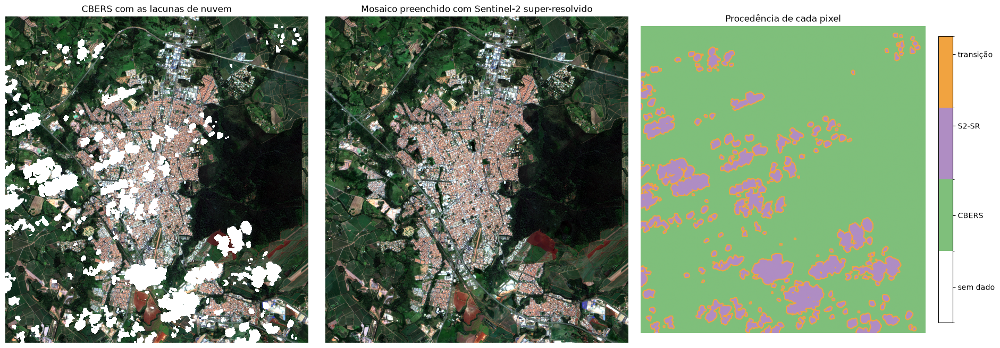

COMPOSIÇÃO DO MOSAICO FINAL (6,456 x 6,968 px de 2 m)

procedência                           pixels         %   área (ha)
CBERS-4A original                 36,744,911    81.68%    14,698.0
Sentinel-2 SR (lacunas)            5,064,610    11.26%     2,025.8
borda (transição CBERS ↔ S2)       3,175,342     7.06%     1,270.1
sem dado                                 545     0.00%         0.2
total                             44,985,408   100.00%    17,994.2


In [26]:
#| label: fig-mosaico-final
#| fig-cap: "CBERS com as lacunas, mosaico preenchido e a procedência de cada pixel."
from matplotlib.colors import BoundaryNorm, ListedColormap

fator_vis = max(1, W_CBERS // 800)
forma = (H_CBERS // fator_vis, W_CBERS // fator_vis)

with rasterio.open(cbers_mascarado) as src:
    antes = src.read((1, 2, 3), out_shape=(3,) + forma,
                     resampling=Resampling.average).astype("float32")
with rasterio.open(mosaico) as src:
    depois = src.read((1, 2, 3), out_shape=(3,) + forma,
                      resampling=Resampling.average).astype("float32")
with rasterio.open(procedencia) as src:
    prov_vis = src.read(1, out_shape=forma, resampling=Resampling.nearest)

for arr in (antes, depois):
    arr[arr <= -9000] = np.nan

cores = ListedColormap(["#ffffff", "#7fbf7b", "#af8dc3", "#f1a340"])
norma = BoundaryNorm([-.5, .5, 1.5, 3.5, 5.5], cores.N)

fig, ax = plt.subplots(1, 3, figsize=(19, 6.5))
ax[0].imshow(np.dstack([ac.stretch(b) for b in antes]))
ax[0].set_title("CBERS com as lacunas de nuvem")
ax[1].imshow(np.dstack([ac.stretch(b) for b in depois]))
ax[1].set_title("Mosaico preenchido com Sentinel-2 super-resolvido")
im = ax[2].imshow(prov_vis, cmap=cores, norm=norma)
ax[2].set_title("Procedência de cada pixel")
cb = fig.colorbar(im, ax=ax[2], ticks=[0, 1, 3, 5], fraction=0.046, pad=0.04)
cb.ax.set_yticklabels(["sem dado", "CBERS", "S2-SR", "transição"])
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

# Composição do mosaico, contada na resolução total (a figura acima é reduzida).
total = sum(stats.values())
ha_por_px = RES_CBERS ** 2 / 10_000
print(f"COMPOSIÇÃO DO MOSAICO FINAL ({W_CBERS:,} x {H_CBERS:,} px de {RES_CBERS:g} m)\n")
print(f"{'procedência':<30}{'pixels':>14}{'%':>10}{'área (ha)':>12}")
for rot, k in [("CBERS-4A original", "cbers"),
               ("Sentinel-2 SR (lacunas)", "s2"),
               ("borda (transição CBERS ↔ S2)", "transicao"),
               ("sem dado", "vazio")]:
    print(f"{rot:<30}{stats[k]:>14,}{stats[k] / total * 100:>9.2f}%{stats[k] * ha_por_px:>12,.1f}")
print(f"{'total':<30}{total:>14,}{100:>9.2f}%{total * ha_por_px:>12,.1f}")

recorte: linhas 3618–4118, colunas 2436–2936 | 54% preenchido com S2


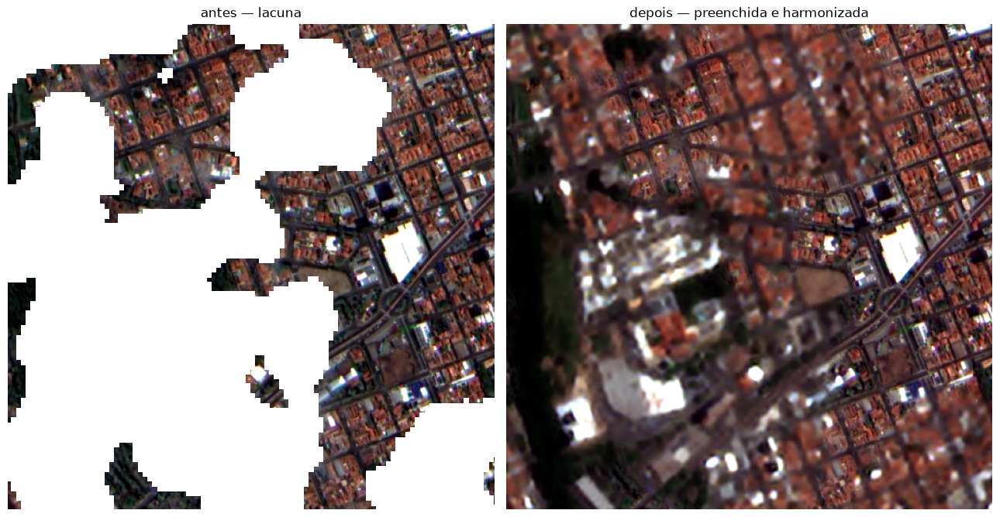

In [27]:
#| label: fig-lacuna-zoom
#| fig-cap: "Zoom numa área com várias lacunas preenchidas, antes e depois."
# O ponto de partida é o centro (mediana) dos pixels preenchidos com o S2.
# Para mover o recorte, mude DESLOC_Y / DESLOC_X (em pixels de 2 m):
#   DESLOC_Y < 0 sobe  | DESLOC_Y > 0 desce
#   DESLOC_X < 0 vai para a esquerda | DESLOC_X > 0 vai para a direita
# LADO é a metade do recorte: 600 -> janela de 1200 x 1200 px (2,4 km).
LADO = 250
DESLOC_Y = -700      # sobe 700 px (1,4 km) em relação ao centro das lacunas
DESLOC_X = 0

if stats["s2"] > 0:
    with rasterio.open(procedencia) as src:
        prov_full = src.read(1)
    ys, xs = np.nonzero(prov_full == COD["s2sr"])
    cy = int(np.median(ys)) + DESLOC_Y
    cx = int(np.median(xs)) + DESLOC_X
    lado = LADO
    y0 = max(0, min(H_CBERS - 2 * lado, cy - lado))
    x0 = max(0, min(W_CBERS - 2 * lado, cx - lado))
    jan = Window(x0, y0, 2 * lado, 2 * lado)
    print(f"recorte: linhas {y0}–{y0 + 2 * lado}, colunas {x0}–{x0 + 2 * lado} "
          f"| {(prov_full[y0:y0 + 2 * lado, x0:x0 + 2 * lado] == COD['s2sr']).mean():.0%} "
          f"preenchido com S2")

    with rasterio.open(cbers_mascarado) as src:
        za = src.read((1, 2, 3), window=jan).astype("float32")
    with rasterio.open(mosaico) as src:
        zd = src.read((1, 2, 3), window=jan).astype("float32")
    for arr in (za, zd):
        arr[arr <= -9000] = np.nan

    fig, ax = plt.subplots(1, 2, figsize=(13, 6.6))
    ax[0].imshow(np.dstack([ac.stretch(b) for b in za]))
    ax[0].set_title("antes — lacuna")
    ax[1].imshow(np.dstack([ac.stretch(b) for b in zd]))
    ax[1].set_title("depois — preenchida e harmonizada")
    for a in ax:
        a.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Nenhuma lacuna foi preenchida — a cena não tinha nuvem sobre a AOI.")

## O que ficou pronto

```
data/interim/S2_<DATA>_10m.tif           mosaico Sentinel-2 (RGBN + delta_days + validade)
data/interim/S2_<DATA>_SR2p5m.tif        super-resolvido pelo SEN2SR
data/interim/S2_<DATA>_2m_coreg.tif      reamostrado e corregistrado na grade do CBERS
data/processed/mosaico_<DATA>_gapfilled.tif    mosaico final     <- o produto do curso
data/processed/mosaico_<DATA>_proveniencia.tif de onde veio cada pixel
```

Abra os dois últimos juntos no seu SIG. A banda de procedência permite saber, para qualquer análise
feita sobre este mosaico, **quais pixels são observação e quais são reconstrução**.

## Limitações que devem ser destacadas

- a saída do SEN2SR é de 2,5 m e foi reamostrada para 2 m;
- a textura da área preenchida é **reconstruída** pelo modelo;
- os pixels de Sentinel-2 vêm de outra data (`delta_days` indica de quantos dias);
- a zona de transição substitui parcialmente pixels de CBERS válidos;
- a normalização radiométrica relativa é empírica (global ou por anel), e não uma correção física
  entre sensores: não compensa a diferença entre as funções de resposta espectral das bandas.

## Referências

- AYBAR, C.; CONTRERAS, J.; DONIKE, S.; PORTALÉS-JULIÀ, E.; MATEO-GARCÍA, G.; GÓMEZ-CHOVA, L.
  A radiometrically and spatially consistent super-resolution framework for Sentinel-2.
  **Remote Sensing of Environment**, v. 334, 115222, 2026. DOI: 10.1016/j.rse.2025.115222.
- CHEN, L.; MA, Y.; LIAN, Y.; ZHANG, H.; YU, Y.; LIN, Y. Radiometric normalization using a
  pseudo-invariant polygon features-based algorithm with contemporaneous Sentinel-2A and Landsat-8
  OLI imagery. **Applied Sciences**, v. 13, n. 4, 2525, 2023. DOI: 10.3390/app13042525.
- CLAVERIE, M.; JU, J.; MASEK, J. G.; DUNGAN, J. L.; VERMOTE, E. F.; ROGER, J.-C.; SKAKUN, S. V.;
  JUSTICE, C. The Harmonized Landsat and Sentinel-2 surface reflectance data set. **Remote Sensing
  of Environment**, v. 219, p. 145-161, 2018. DOI: 10.1016/j.rse.2018.09.002.
- PINTO, C.; PONZONI, F.; CASTRO, R.; LEIGH, L.; MISHRA, N.; AARON, D.; HELDER, D. First in-flight
  radiometric calibration of MUX and WFI on-board CBERS-4. **Remote Sensing**, v. 8, n. 5, 405,
  2016. DOI: 10.3390/rs8050405.
- SCHEFFLER, D.; HOLLSTEIN, A.; DIEDRICH, H.; SEGL, K.; HOSTERT, P. AROSICS: an automated and
  robust open-source image co-registration software for multi-sensor satellite data. **Remote
  Sensing**, v. 9, n. 7, 676, 2017. DOI: 10.3390/rs9070676.
- YUAN, D.; ELVIDGE, C. D. Comparison of relative radiometric normalization techniques. **ISPRS
  Journal of Photogrammetry and Remote Sensing**, v. 51, n. 3, p. 117-126, 1996.
  DOI: 10.1016/0924-2716(96)00018-4.
- [SEN2SR / tacofoundation no Hugging Face](https://huggingface.co/tacofoundation/sen2sr)
- [Sentinel-2 L2A no Planetary Computer](https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a)
- ESA. **Sentinel-2 processing baseline 04.00**: offset de reflectância.